# 07 · 苍穹外卖：缓存商品、购物车

来源：本地 `讲义.rar / 讲义/day07/苍穹外卖-day07.md` 与 `PPT.rar / PPT/day07-缓存商品、购物车.pptx`，压缩包位于 `D:/baidudisk/BaiduNetdiskDownload`。整理日期：2026-10-09。

本章给第06章的商品浏览加入缓存：菜品使用RedisTemplate手动读写，套餐使用Spring Cache注解；随后实现添加、查看和清空当前用户购物车。保留讲义的28段代码、表格与配图，对照70页PPT整理；补充说明、勘误与验收清单独立标注，配图已内嵌，可离线阅读。

跟练依赖已有菜品与套餐管理、用户登录和JWT拦截器、BaseContext、Redis连接及商品浏览接口。商品缓存存入Redis，购物车记录保存在MySQL的shopping_cart表，二者不要混淆。

> **重点勘误。** 原菜品缓存只把非空列表当作命中，空分类会反复查数据库；原购物车动态SQL在dishFlavor为null时省略口味条件，可能误匹配；若BaseContext用户id缺失，列表查询还可能省略用户条件。后面分别给出修正。原文关于“时刻一致”的说法也需限定：更新数据库后删除缓存是常用策略，但不自动保证并发下严格一致。


## 跟练路线、接口与存储速查（补充）

| 顺序 | 功能 | 核心规则 |
| --- | --- | --- |
| 1 | 缓存菜品 | 按分类缓存菜品与口味，修改相关数据后失效 |
| 2 | 缓存套餐 | Cacheable读缓存，CacheEvict清理，确认底层CacheManager |
| 3 | 添加购物车 | 菜品或套餐二选一，同用户同商品同规格增加一份 |
| 4 | 查看购物车 | 只查询当前用户，不接收客户端指定的userId |
| 5 | 清空购物车 | 仅删除当前用户的shopping_cart记录 |

### 主要接口

| 功能 | 方法与后端路径 | 参数与返回 |
| --- | --- | --- |
| 用户菜品列表 | `GET /user/dish/list` | Query：categoryId；沿用第06章返回结构 |
| 用户套餐列表 | `GET /user/setmeal/list` | Query：categoryId；沿用第06章返回结构 |
| 添加购物车 | `POST /user/shoppingCart/add` | JSON：dishId或setmealId，菜品可带dishFlavor |
| 查看购物车 | `GET /user/shoppingCart/list` | 无业务参数；返回当前用户的购物车列表 |
| 清空购物车 | `DELETE /user/shoppingCart/clean` | 无业务参数；删除当前用户全部购物车行 |

用户请求携带第06章约定的authentication请求头。购物车的userId来自JWT解析后的BaseContext，不能让客户端通过参数选择其他人的购物车。

管理端新增、修改、批量删除、启停售的接口继续沿用已有实现，本章增加缓存失效逻辑，不替换原事务、关联检查或状态校验。讲义只实现购物车添加、查看、清空；页面有减号不表示本章已实现减少数量接口。

### 存储与缓存对象

| 数据 | 位置或key | 实际对象 |
| --- | --- | --- |
| 某分类菜品 | Redis：dish_分类id，例如dish_17 | List<DishVO>，包含口味 |
| 某分类套餐 | RedisCacheManager默认前缀下：setmealCache::分类id | 原Controller返回的Result<List<Setmeal>> |
| Spring Cache演示用户 | 演示缓存userCache::用户id | 演示工程User，不是微信登录模块 |
| 用户购物车 | MySQL：shopping_cart | 商品、规格、数量、单价、用户id |

Redis的具体逻辑数据库沿用连接配置，按第05章讲义一般为db10。缓存名称前缀可以配置，表中的Spring Cache key是默认规则，不是所有项目不可修改的格式。

### 菜品缓存流程

```text
查询分类商品 → 生成dish_分类id → 读Redis
    命中：返回缓存列表
    未命中：查菜品与口味 → 写Redis → 返回列表

后台修改商品 → 数据库写入成功 → 删除受影响缓存
    → 下一次用户读取重新查数据库并填入缓存
```

购物车添加则走另一条链路：用户token → 当前userId → 查匹配购物车行 → 已有行数量加1，或查询商品后插入新行。


## 课程内容

> **PPT对照：** 第1—3页。

- 缓存菜品
- 缓存套餐
- 添加购物车
- 查看购物车
- 清空购物车


功能实现：**缓存商品**、**购物车**

**效果图：**

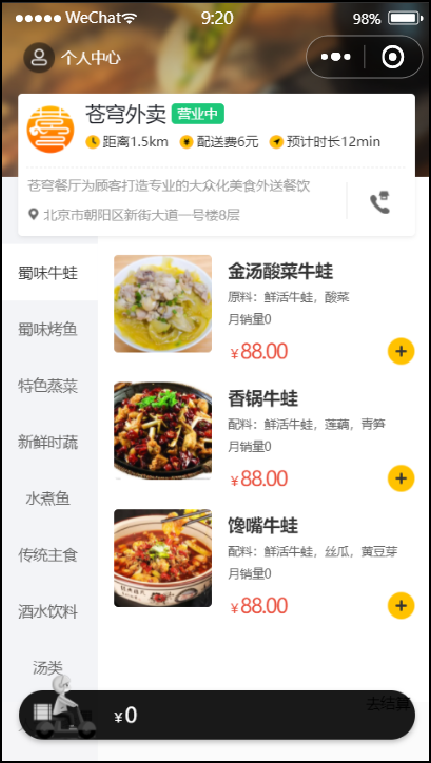 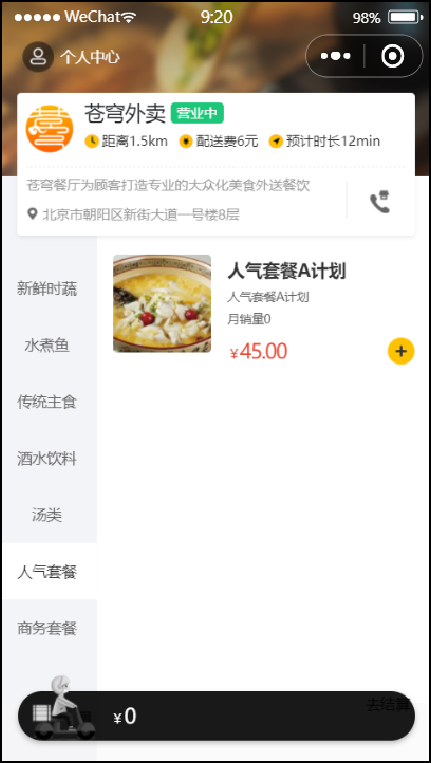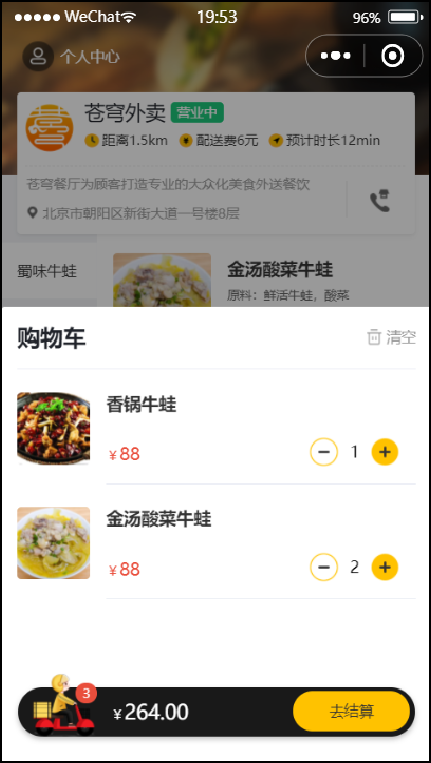


## 1. 缓存菜品

> **PPT对照：** 第4—18页。


### 1.1 问题说明

> **PPT对照：** 第5页。

用户端小程序展示的菜品数据都是通过查询数据库获得，如果用户端访问量比较大，数据库访问压力随之增大。

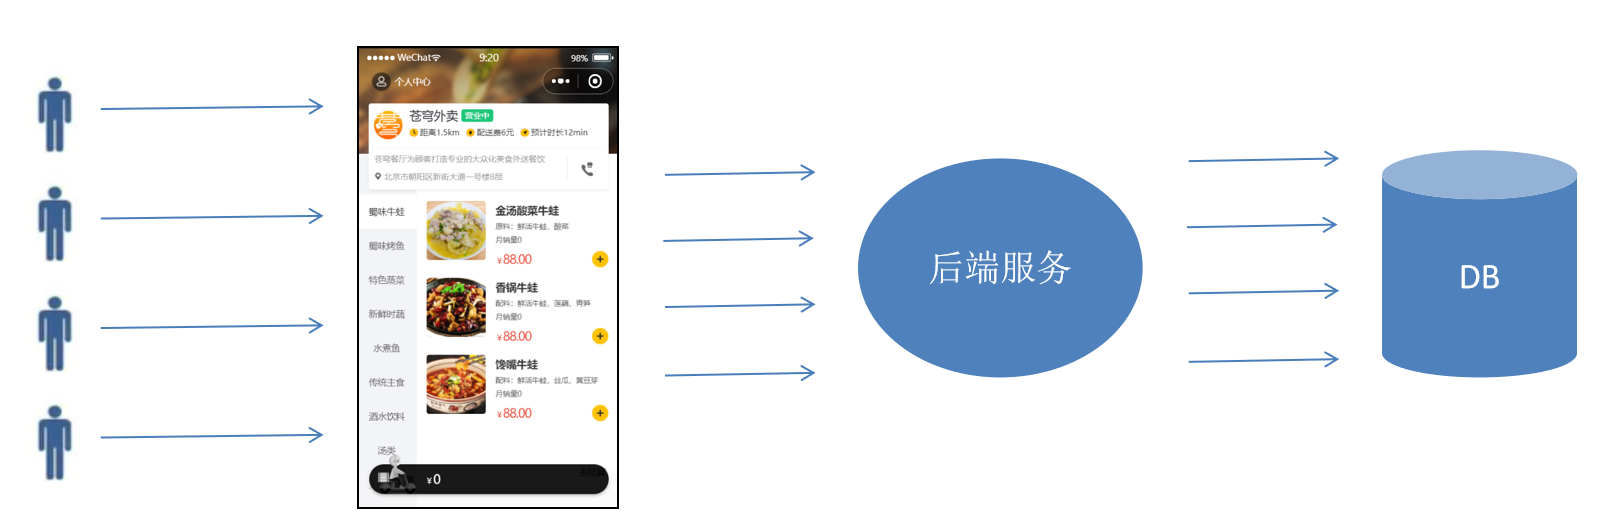 

**结果：**系统响应慢、用户体验差


### 缓存降低哪一部分压力（补充）

第06章菜品浏览先查分类下的菜品，再逐个查询口味；同分类多次访问会重复执行这些SQL。缓存整个List<DishVO>可以让命中请求跳过这组查询。

缓存减少数据库读压力，但增加了Redis访问、序列化、失效与故障处理。评价效果应看SQL次数、命中率和实际响应时间，不是仅看到Redis有一个key就判断性能提升。

菜单列表适合按分类共享缓存，购物车则随用户不同而不同，不能把商品列表的分类key直接用于缓存所有用户购物车。


### 1.2 实现思路

> **PPT对照：** 第7—8页。

通过Redis来缓存菜品数据，减少数据库查询操作。

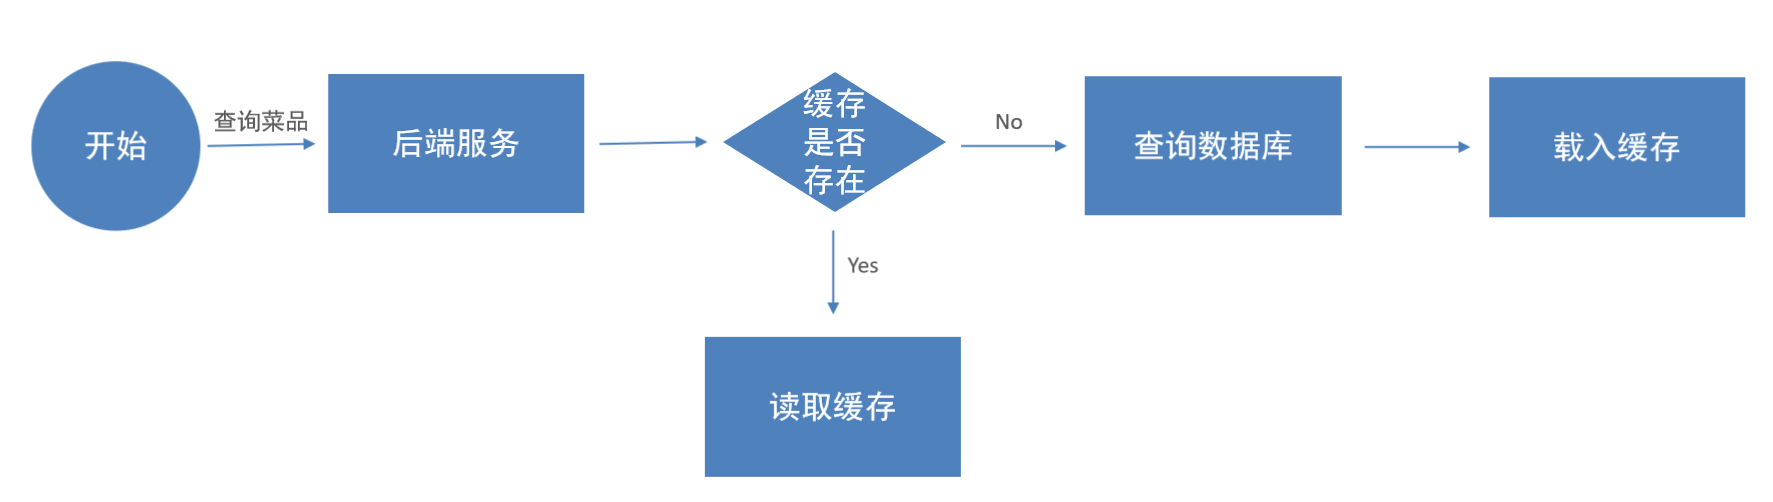 

**缓存逻辑分析：**

- 每个分类下的菜品保存一份缓存数据
- 数据库中菜品数据有变更时清理缓存数据

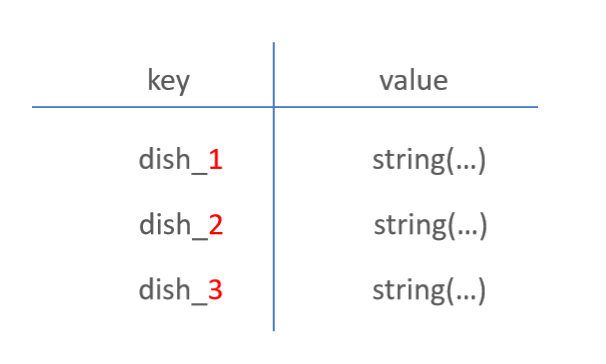


### 缓存单位决定失效范围（补充）

这里缓存的是一个分类下所有起售菜品及口味，不是每个菜品一个key。修改某个菜品的价格、图片、名称、口味或状态，都可能影响该分类缓存。

新增只影响新增分类；修改菜品所属分类时同时影响旧分类和新分类。原课程对修改、删除、启停售清理dish_*，范围较大但能覆盖多分类，不能优化成“只删DTO的新分类”而遗漏旧分类。

如果分类启禁用或关联业务改变了商品可见性，也要按实际展示规则考虑缓存失效。缓存命中不能绕过原用户鉴权；分类可见性要求变化时，缓存数据也应遵守同一规则。


### 1.3 代码开发

> **PPT对照：** 第10—16页。

**修改用户端接口 DishController 的 list 方法，加入缓存处理逻辑：**

```java
	@Autowired
    private RedisTemplate redisTemplate;
	/**
     * 根据分类id查询菜品
     *
     * @param categoryId
     * @return
     */
    @GetMapping("/list")
    @ApiOperation("根据分类id查询菜品")
    public Result<List<DishVO>> list(Long categoryId) {

        //构造redis中的key，规则：dish_分类id
        String key = "dish_" + categoryId;

        //查询redis中是否存在菜品数据
        List<DishVO> list = (List<DishVO>) redisTemplate.opsForValue().get(key);
        if(list != null && list.size() > 0){
            //如果存在，直接返回，无须查询数据库
            return Result.success(list);
        }
		////////////////////////////////////////////////////////
        Dish dish = new Dish();
        dish.setCategoryId(categoryId);
        dish.setStatus(StatusConstant.ENABLE);//查询起售中的菜品

        //如果不存在，查询数据库，将查询到的数据放入redis中
        list = dishService.listWithFlavor(dish);
        ////////////////////////////////////////////////////////
        redisTemplate.opsForValue().set(key, list);

        return Result.success(list);
    }
```

为了保证**数据库**和**Redis**中的数据保持一致，修改**管理端接口 DishController** 的相关方法，加入清理缓存逻辑。

需要改造的方法：

- 新增菜品
- 修改菜品
- 批量删除菜品
- 起售、停售菜品

**抽取清理缓存的方法：**

在管理端DishController中添加

```java
	@Autowired
    private RedisTemplate redisTemplate;
	/**
     * 清理缓存数据
     * @param pattern
     */
    private void cleanCache(String pattern){
        Set keys = redisTemplate.keys(pattern);
        redisTemplate.delete(keys);
    }
```

**调用清理缓存的方法，保证数据一致性：**

**1). 新增菜品优化**

```java
	/**
     * 新增菜品
     *
     * @param dishDTO
     * @return
     */
    @PostMapping
    @ApiOperation("新增菜品")
    public Result save(@RequestBody DishDTO dishDTO) {
        log.info("新增菜品：{}", dishDTO);
        dishService.saveWithFlavor(dishDTO);

        //清理缓存数据
        String key = "dish_" + dishDTO.getCategoryId();
        cleanCache(key);
        return Result.success();
    }
```

**2). 菜品批量删除优化**

```java
	/**
     * 菜品批量删除
     *
     * @param ids
     * @return
     */
    @DeleteMapping
    @ApiOperation("菜品批量删除")
    public Result delete(@RequestParam List<Long> ids) {
        log.info("菜品批量删除：{}", ids);
        dishService.deleteBatch(ids);

        //将所有的菜品缓存数据清理掉，所有以dish_开头的key
        cleanCache("dish_*");

        return Result.success();
    }
```

**3). 修改菜品优化**

```java
	/**
     * 修改菜品
     *
     * @param dishDTO
     * @return
     */
    @PutMapping
    @ApiOperation("修改菜品")
    public Result update(@RequestBody DishDTO dishDTO) {
        log.info("修改菜品：{}", dishDTO);
        dishService.updateWithFlavor(dishDTO);

        //将所有的菜品缓存数据清理掉，所有以dish_开头的key
        cleanCache("dish_*");

        return Result.success();
    }
```

**4). 菜品起售停售优化**

```java
	/**
     * 菜品起售停售
     *
     * @param status
     * @param id
     * @return
     */
    @PostMapping("/status/{status}")
    @ApiOperation("菜品起售停售")
    public Result<String> startOrStop(@PathVariable Integer status, Long id) {
        dishService.startOrStop(status, id);

        //将所有的菜品缓存数据清理掉，所有以dish_开头的key
        cleanCache("dish_*");

        return Result.success();
    }
```


### 空列表命中、期限与清理方式（补充与勘误）

#### 1. 空分类也可以缓存

原 `list != null && list.size() > 0`使Redis中的空列表永远不能命中。结果为[]的分类每次仍查数据库，虽然代码已经把[]写进Redis。

可将用户端list改为以下版本，沿用已有DishService、RedisTemplate和 imports，并补RequestParam：

```java
@GetMapping("/list")
public Result<List<DishVO>> list(@RequestParam("categoryId") Long categoryId) {
    if (categoryId == null || categoryId <= 0) {
        throw new IllegalArgumentException("分类id不合法");
    }
    String key = "dish_" + categoryId;
    List<DishVO> list = (List<DishVO>) redisTemplate.opsForValue().get(key);
    if (list != null) {
        return Result.success(list);
    }

    Dish dish = new Dish();
    dish.setCategoryId(categoryId);
    dish.setStatus(StatusConstant.ENABLE);
    list = dishService.listWithFlavor(dish);
    // 原MyBatis列表查询约定：无记录返回空列表，不返回null。
    long seconds = list.isEmpty() ? 30 : 300;
    redisTemplate.opsForValue().set(key, list, seconds,
            java.util.concurrent.TimeUnit.SECONDS);
    return Result.success(list);
}
```

30秒和300秒是本补充的示例期限，不是原讲义要求。短期空结果缓存减少反复查库，新增数据后仍需删除对应key。参数校验应接入已有统一异常处理器。

原RedisTemplate继承第05章的序列化规则，value默认JDK；List、DishVO及内部DishFlavor都要可序列化。StringRedisTemplate不能直接存List对象。更换格式或类结构后要计划迁移/失效旧缓存，不能只修改强制转换来解决不兼容。

#### 2. 精确key不用KEYS查找

新增菜品时已知道分类，可直接删除：

```java
redisTemplate.delete("dish_" + dishDTO.getCategoryId());
```

原cleanCache使用KEYS(pattern)再删除。保留小规模课程示例时至少处理空结果：

```java
private void cleanCache(String pattern) {
    Set keys = redisTemplate.keys(pattern);
    if (keys != null && !keys.isEmpty()) {
        redisTemplate.delete(keys);
    }
}
```

KEYS会扫描当前库，key很多时影响其他请求；批量清理应按实际规模采用SCAN分批或维护分类key集合。不能用清空Redis数据库代替清理dish_*，否则营业状态和其他缓存也会消失。

#### 3. 写数据库后删缓存，不是严格实时一致

原顺序是先调用事务Service，再清理缓存。菜品/口味写入的事务规则沿用第03章，不应为了加缓存而删掉它们。

并发时仍可能发生：读请求查到旧数据库结果，写请求提交并删缓存，读请求随后又把旧结果写入Redis。TTL只能限制陈旧数据持续时间，不会让这个竞态消失。

数据库写入成功而Redis删除失败时，两者也不会自动一起回滚；可能出现请求报错但数据库已经修改。实际项目应定义失效重试、事务提交后处理和监控等策略。若把清理移入事务方法，注意在提交之后执行，避免回滚或未提交数据被其他读取覆盖。

如果菜品停售会连带改变套餐状态，或其他菜品写入影响套餐列表，则还需清理setmealCache；仅清dish_*不能覆盖另一份缓存。


### 1.4 功能测试

> **PPT对照：** 第18页。

可以通过如下方式进行测试：

- 查看控制台sql
- 前后端联调
- 查看Redis中的缓存数据

以**加入缓存**、**菜品修改**两个功能测试为例，通过前后端联调方式，查看控制台sql的打印和Redis中的缓存数据变化。


**1). 加入缓存**

当第一次查询某个分类的菜品时，会从数据为中进行查询，同时将查询的结果存储到Redis中，在后绪的访问，若查询相同分类的菜品时，直接从Redis缓存中查询，不再查询数据库。

**登录小程序：**选择蜀味牛蛙(id=17)

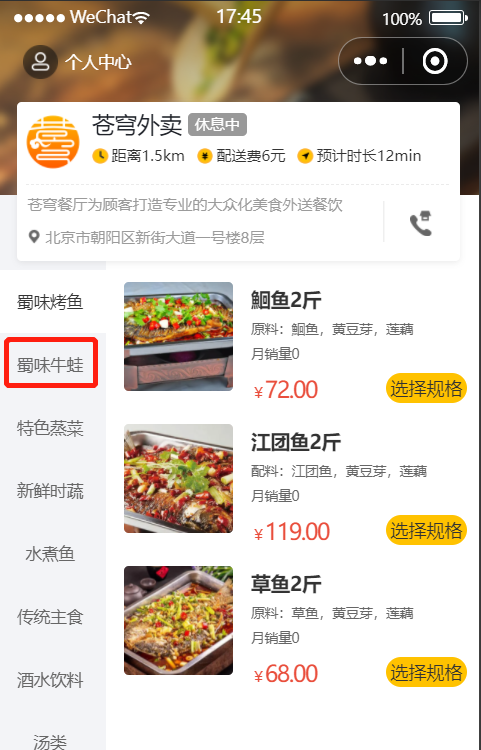 

**查看控制台sql：**有查询语句，说明是从数据库中进行查询

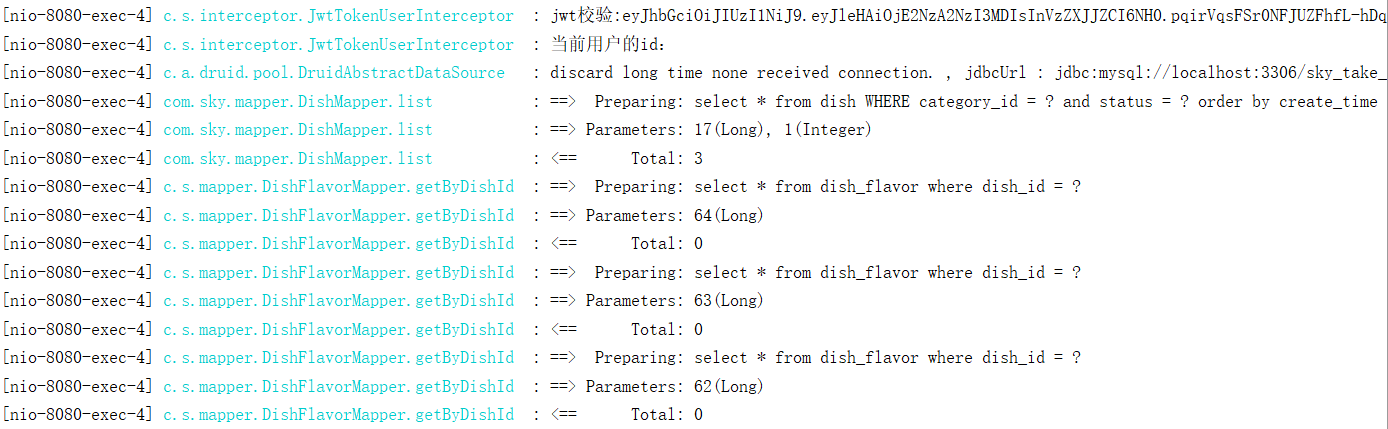 

**查看Redis中的缓存数据：**说明缓存成功

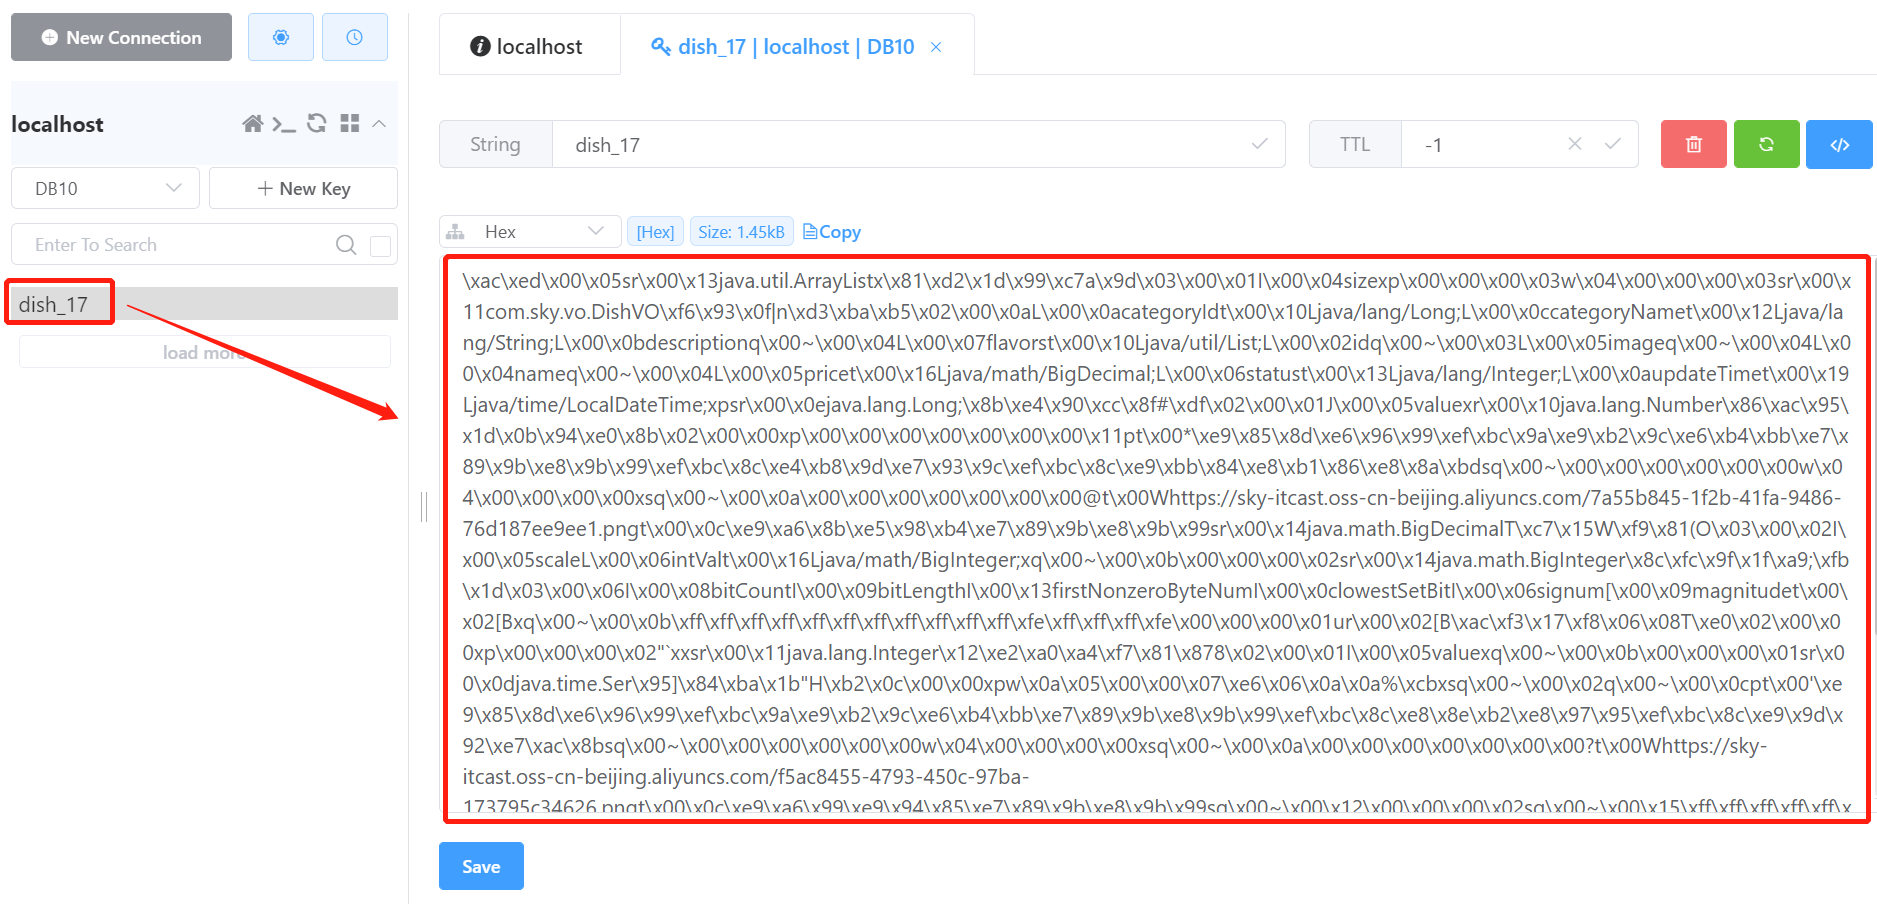 

**再次访问：**选择蜀味牛蛙(id=17)

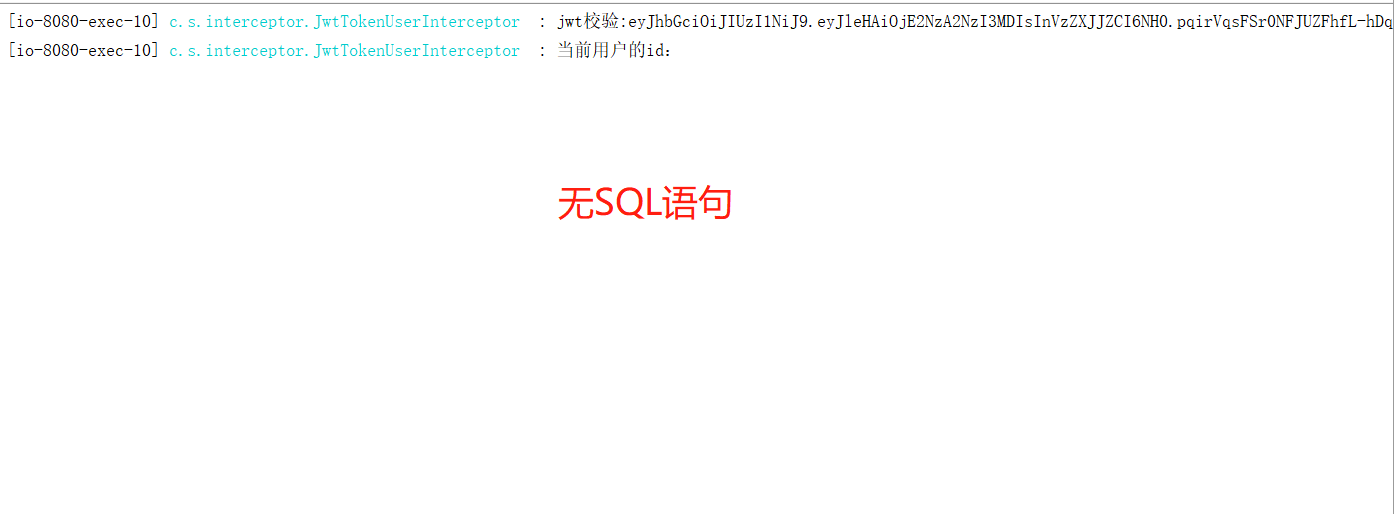 

说明是从Redis中查询的数据。


**2). 菜品修改**

当在后台修改菜品数据时，为了保证Redis缓存中的数据和数据库中的数据时刻保持一致，当修改后，需要清空对应的缓存数据。用户再次访问时，还是先从数据库中查询，同时再把查询的结果存储到Redis中，这样，就能保证缓存和数据库的数据保持一致。

**进入后台：**修改蜀味牛蛙分类下的任意一个菜品，当前分类的菜品数据已在Redis中缓存

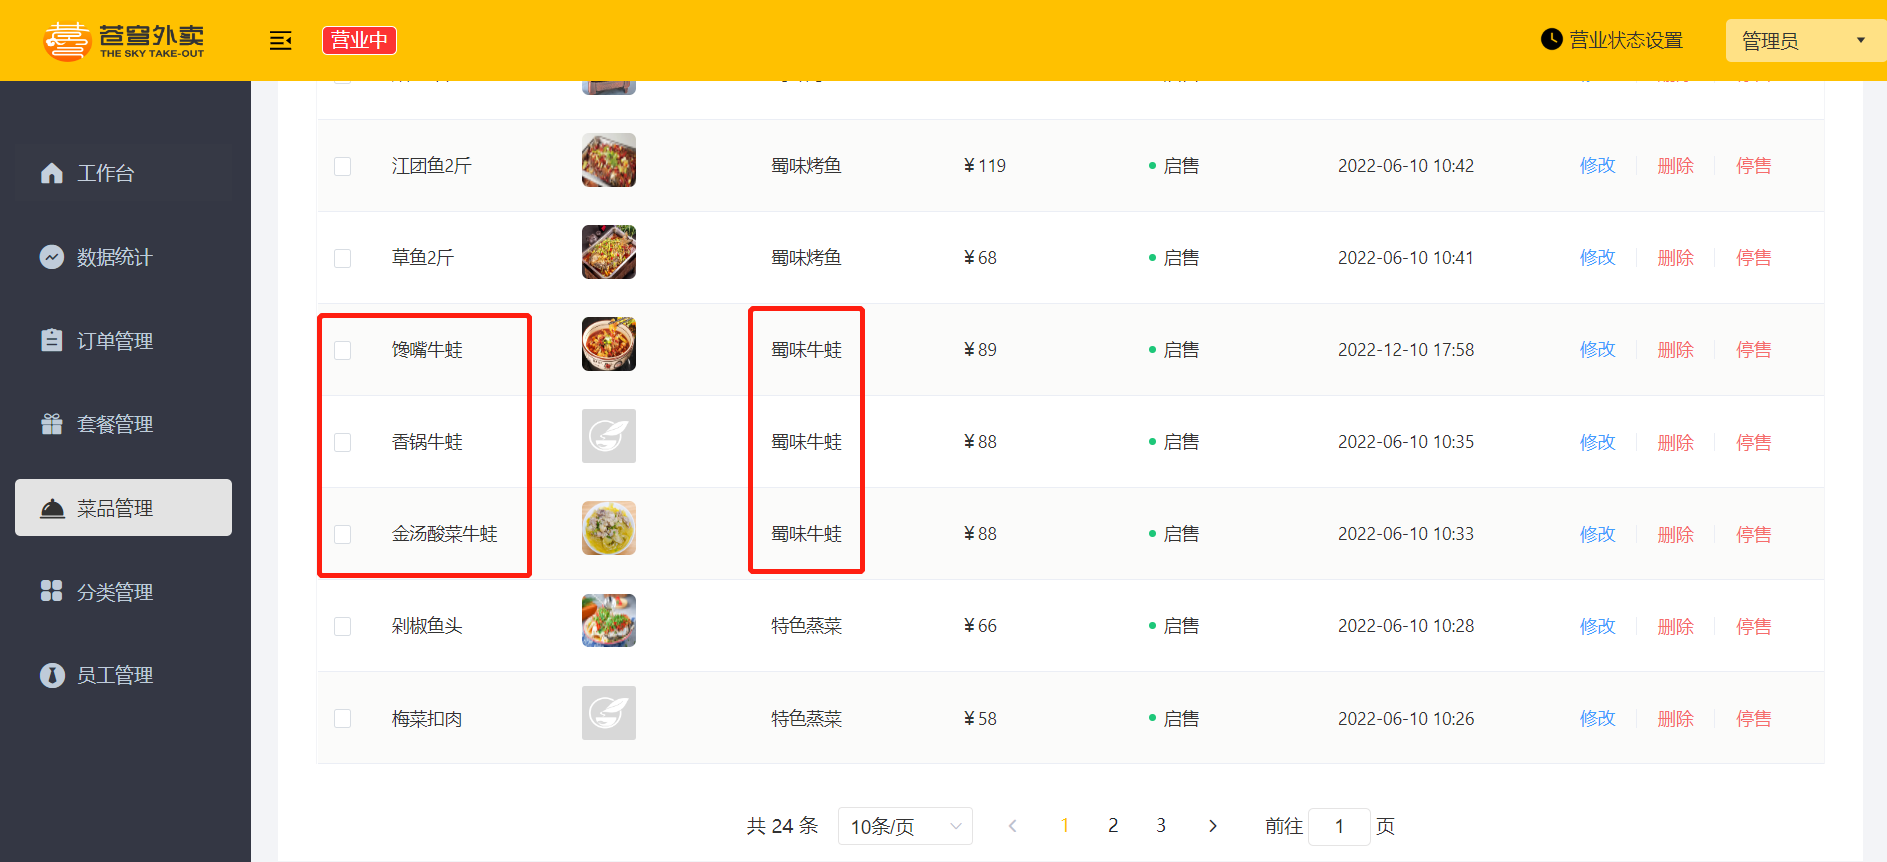 

**修改：**

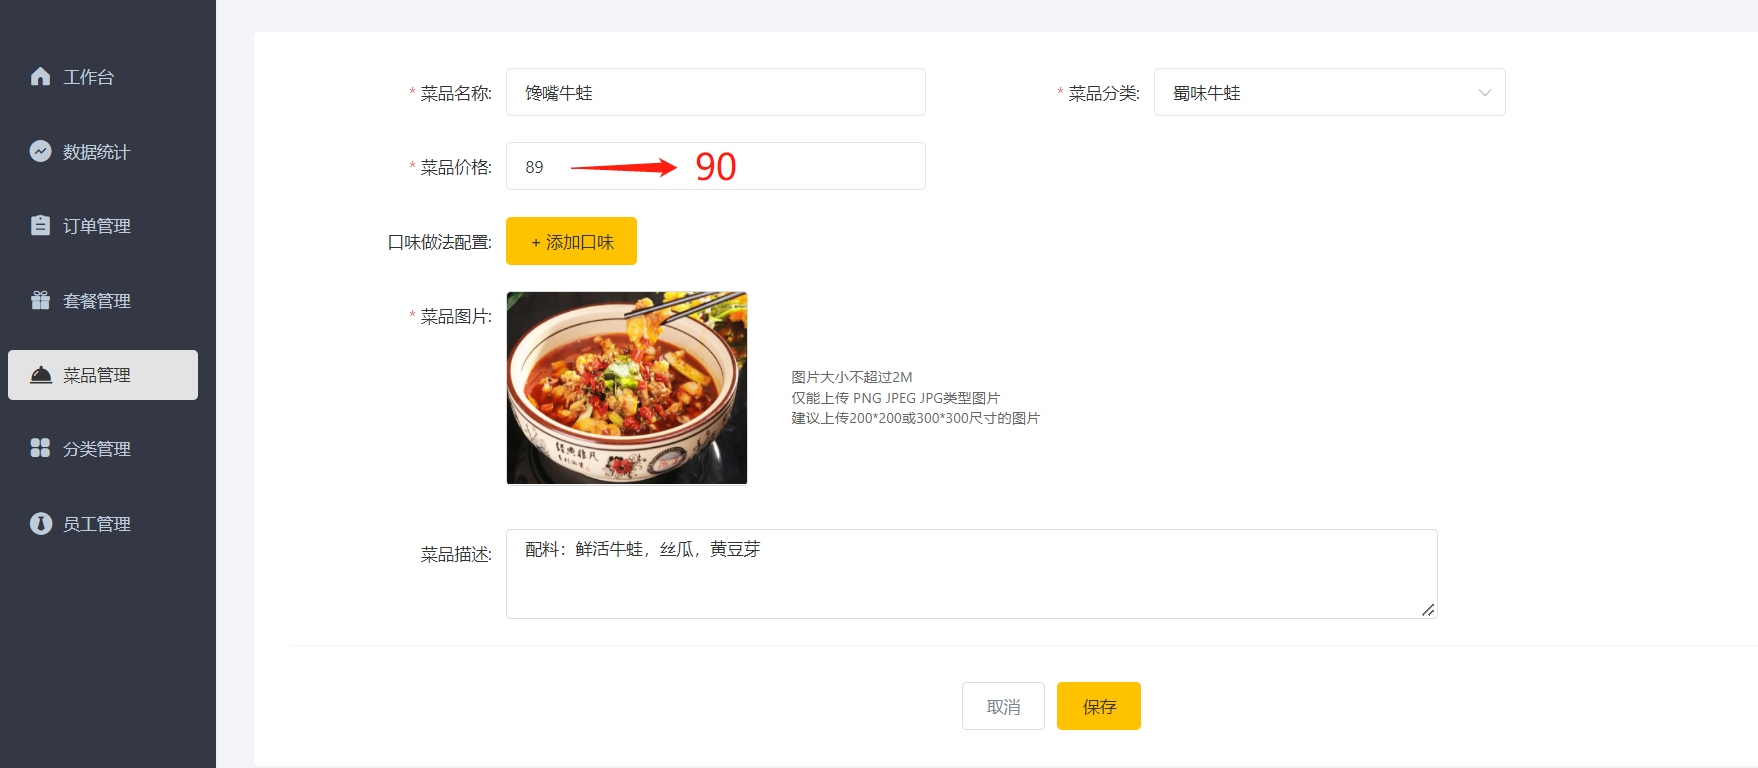 

**查看Redis中的缓存数据：**说明修改时，已清空缓存

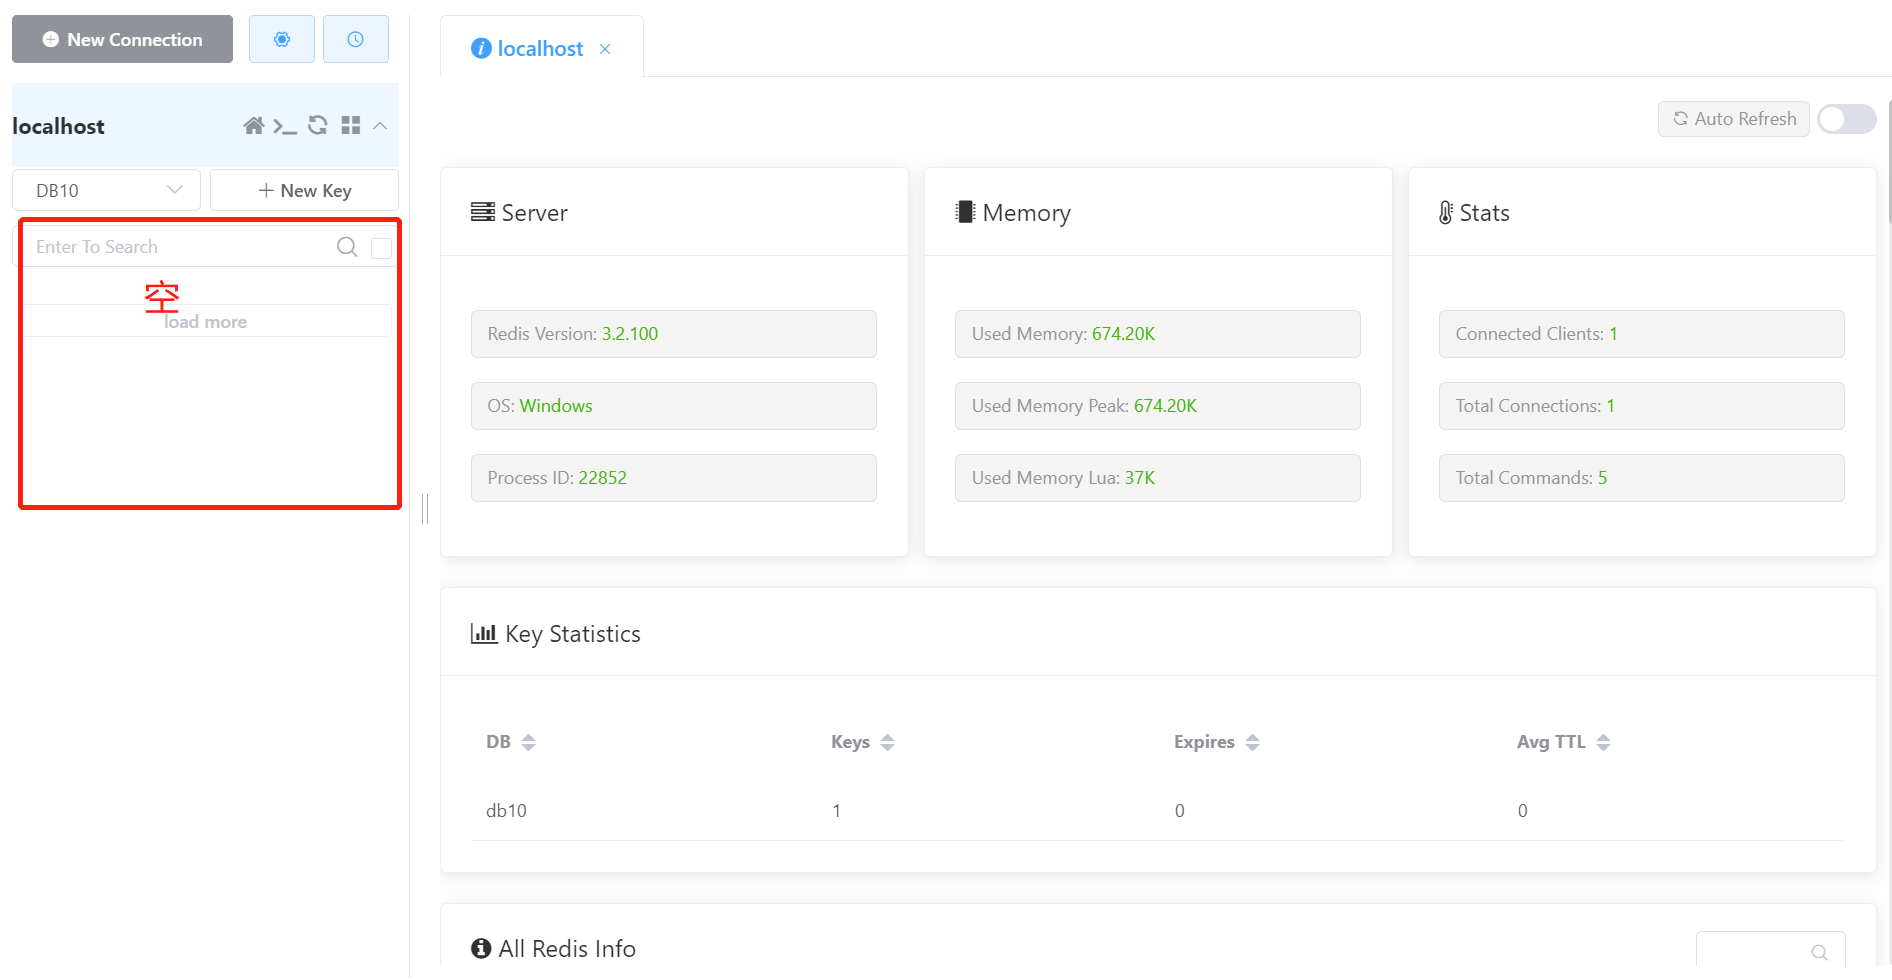 

用户再次访问同一个菜品分类时，需要先查询数据库，再把结果同步到Redis中，保证了两者数据一致性。

其它功能测试步骤基本一致，自已测试即可。


### 菜品缓存验收矩阵（补充）

| 场景 | 核对结果 |
| --- | --- |
| 分类第一次查询 | 查菜品与口味SQL，Redis生成dish_分类id |
| 相同分类第二次查询 | 命中缓存，不再执行这组商品SQL |
| 无起售菜品的分类 | 修正后空列表也命中，按短TTL失效 |
| 新增菜品 | 对应分类缓存失效，再查询看到新数据 |
| 修改价格或口味 | 缓存失效，重新查询返回最新内容 |
| 修改所属分类 | 旧、新分类结果都正确，不残留旧归属 |
| 删除、起售、停售 | 缓存失效，列表可见范围符合状态 |
| 缓存到期 | 下次重新查库并补回缓存 |

使用测试库中真实分类id，不照搬截图中的17。测试同时看响应内容、SQL和Redis，并确认正查看Java配置的数据库。单独刷新页面且无明显变化不能证明失效正确。


### 1.5 代码提交

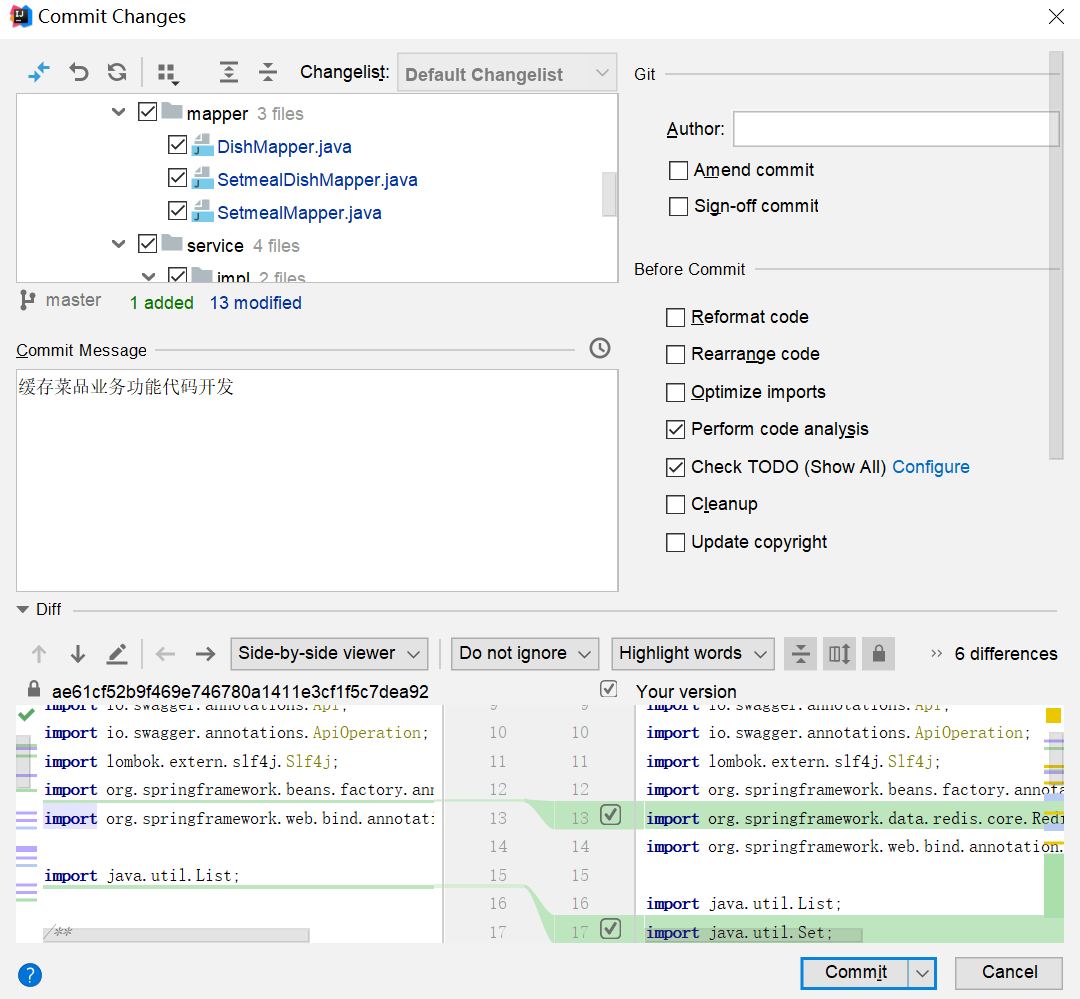 

后续步骤和其它功能代码提交一致，不再赘述。


## 2. 缓存套餐

> **PPT对照：** 第20—30页。


### 2.1 Spring Cache

> **PPT对照：** 第21—23页，详细入门案例由讲义展开。

#### 2.1.1 介绍

Spring Cache 是一个框架，实现了基于注解的缓存功能，只需要简单地加一个注解，就能实现缓存功能。

Spring Cache 提供了一层抽象，底层可以切换不同的缓存实现，例如：

- EHCache
- Caffeine
- Redis(常用)

**起步依赖：**

```xml
<dependency>
	<groupId>org.springframework.boot</groupId>
	<artifactId>spring-boot-starter-cache</artifactId>  		            		       	 <version>2.7.3</version> 
</dependency>
```


#### 2.1.2 常用注解

在SpringCache中提供了很多缓存操作的注解，常见的是以下的几个：

| **注解**       | **说明**                                                     |
| -------------- | ------------------------------------------------------------ |
| @EnableCaching | 开启缓存注解功能，通常加在启动类上                           |
| @Cacheable     | 在方法执行前先查询缓存中是否有数据，如果有数据，则直接返回缓存数据；如果没有缓存数据，调用方法并将方法返回值放到缓存中 |
| @CachePut      | 将方法的返回值放到缓存中                                     |
| @CacheEvict    | 将一条或多条数据从缓存中删除                                 |

在spring boot项目中，使用缓存技术只需在项目中导入相关缓存技术的依赖包，并在启动类上使用@EnableCaching开启缓存支持即可。

例如，使用Redis作为缓存技术，只需要导入Spring data Redis的maven坐标即可。


#### 2.1.3 入门案例

**1). 环境准备**

**导入基础工程:**底层已使用Redis缓存实现

基础环境的代码，在我们今天的资料中已经准备好了， 大家只需要将这个工程导入进来就可以了。导入进来的工程结构如下： 

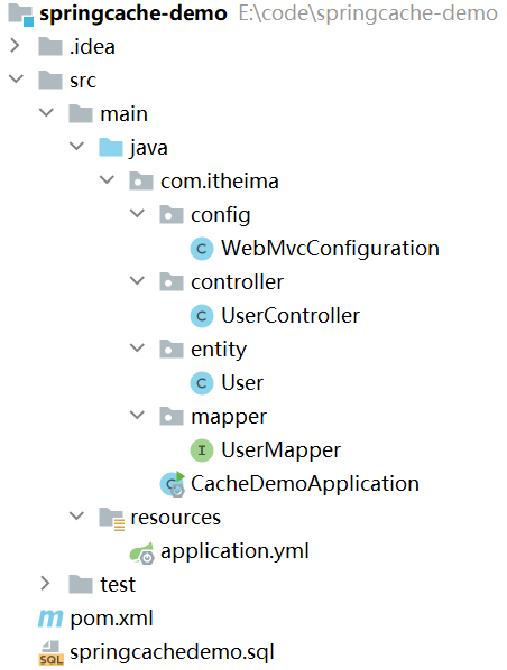 

**数据库准备:**

创建名为spring_cache_demo数据库，将springcachedemo.sql脚本直接导入数据库中。

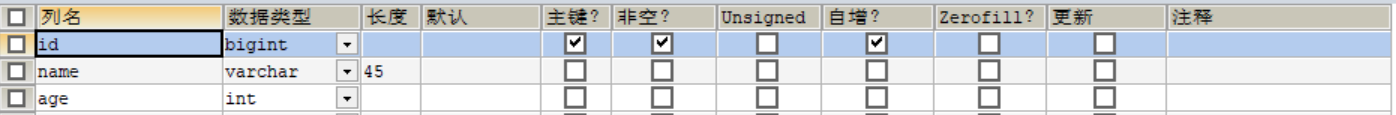 

**引导类上加@EnableCaching:**

```java
package com.itheima;

import lombok.extern.slf4j.Slf4j;
import org.springframework.boot.SpringApplication;
import org.springframework.boot.autoconfigure.SpringBootApplication;
import org.springframework.cache.annotation.EnableCaching;

@Slf4j
@SpringBootApplication
@EnableCaching//开启缓存注解功能
public class CacheDemoApplication {
    public static void main(String[] args) {
        SpringApplication.run(CacheDemoApplication.class,args);
        log.info("项目启动成功...");
    }
}
```


**2). @CachePut注解**

**@CachePut 说明：** 

 作用: 将方法返回值，放入缓存

 value: 缓存的名称, 每个缓存名称下面可以有很多key

 key: 缓存的key  ----------> 支持Spring的表达式语言SPEL语法


**在save方法上加注解@CachePut**

当前UserController的save方法是用来保存用户信息的，我们希望在该用户信息保存到数据库的同时，也往缓存中缓存一份数据，我们可以在save方法上加上注解 @CachePut，用法如下：

```java
	/**
	* CachePut：将方法返回值放入缓存
	* value：缓存的名称，每个缓存名称下面可以有多个key
	* key：缓存的key
	*/
	@PostMapping
    @CachePut(value = "userCache", key = "#user.id")//key的生成：userCache::1
    public User save(@RequestBody User user){
        userMapper.insert(user);
        return user;
    }
```

**说明：**key的写法如下

\#user.id : #user指的是方法形参的名称, id指的是user的id属性 , 也就是使用user的id属性作为key ;

\#result.id : #result代表方法返回值，该表达式 代表以返回对象的id属性作为key ；

\#p0.id：#p0指的是方法中的第一个参数，id指的是第一个参数的id属性,也就是使用第一个参数的id属性作为key ;

\#a0.id：#a0指的是方法中的第一个参数，id指的是第一个参数的id属性,也就是使用第一个参数的id属性作为key ;

\#root.args[0].id:#root.args[0]指的是方法中的第一个参数，id指的是第一个参数的id属性,也就是使用第一个参数

的id属性作为key ;

**启动服务,通过swagger接口文档测试，访问UserController的save()方法**

因为id是自增，所以不需要设置id属性

 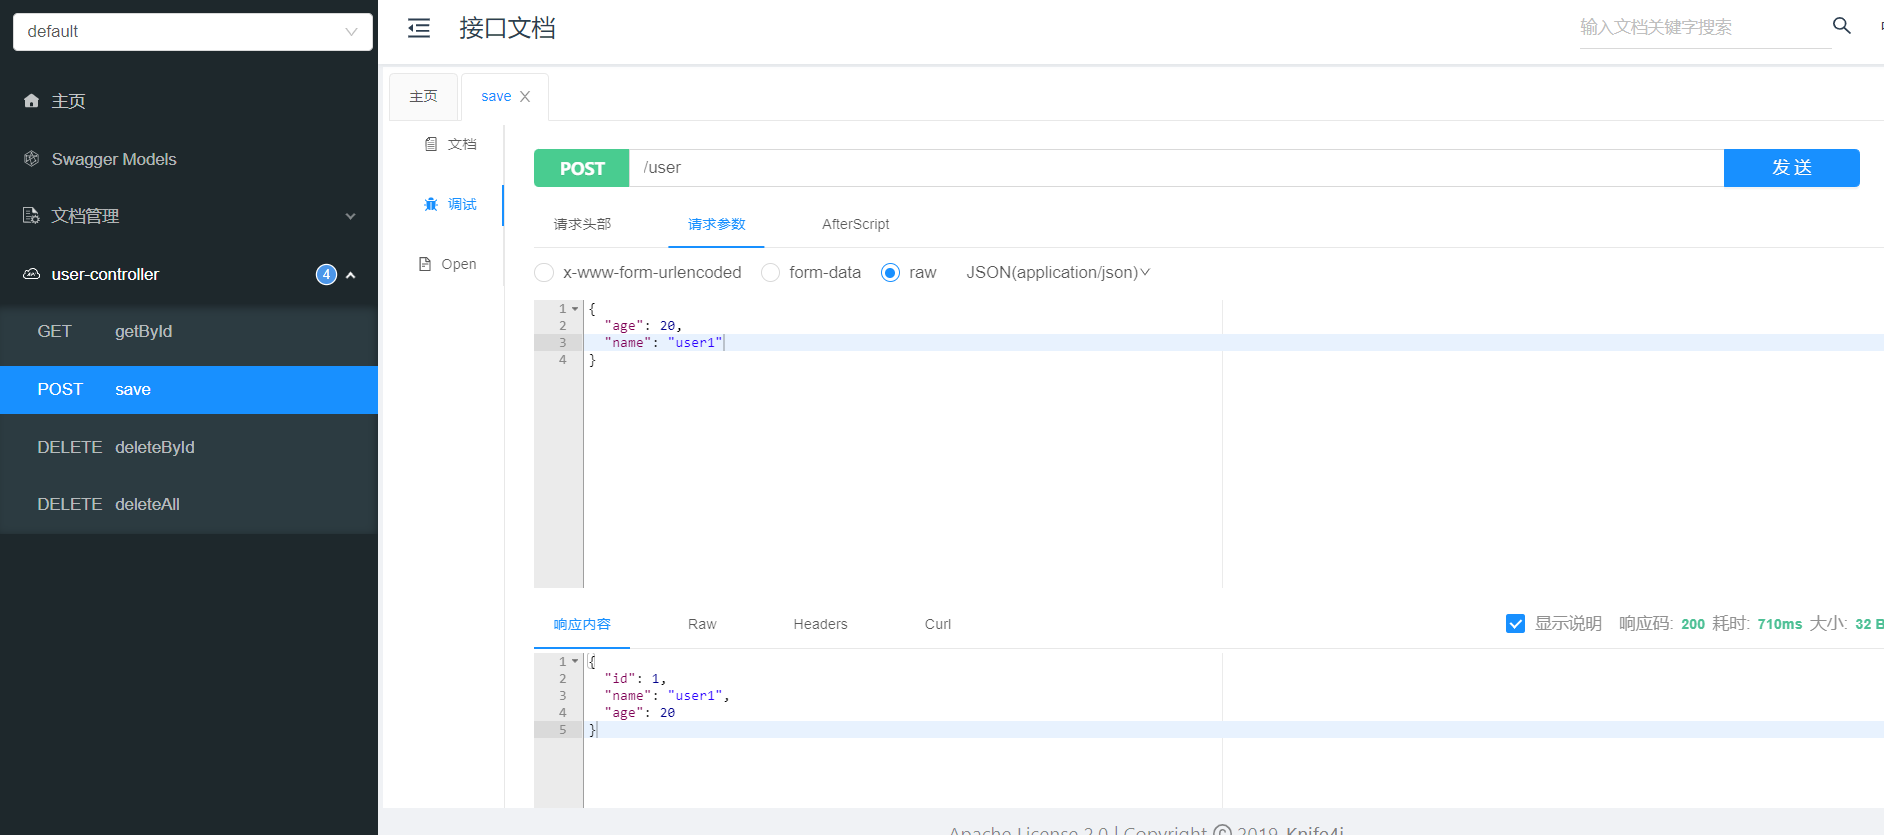 

**查看user表中的数据**

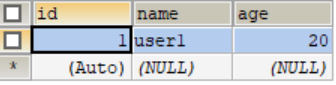 

**查看Redis中的数据**

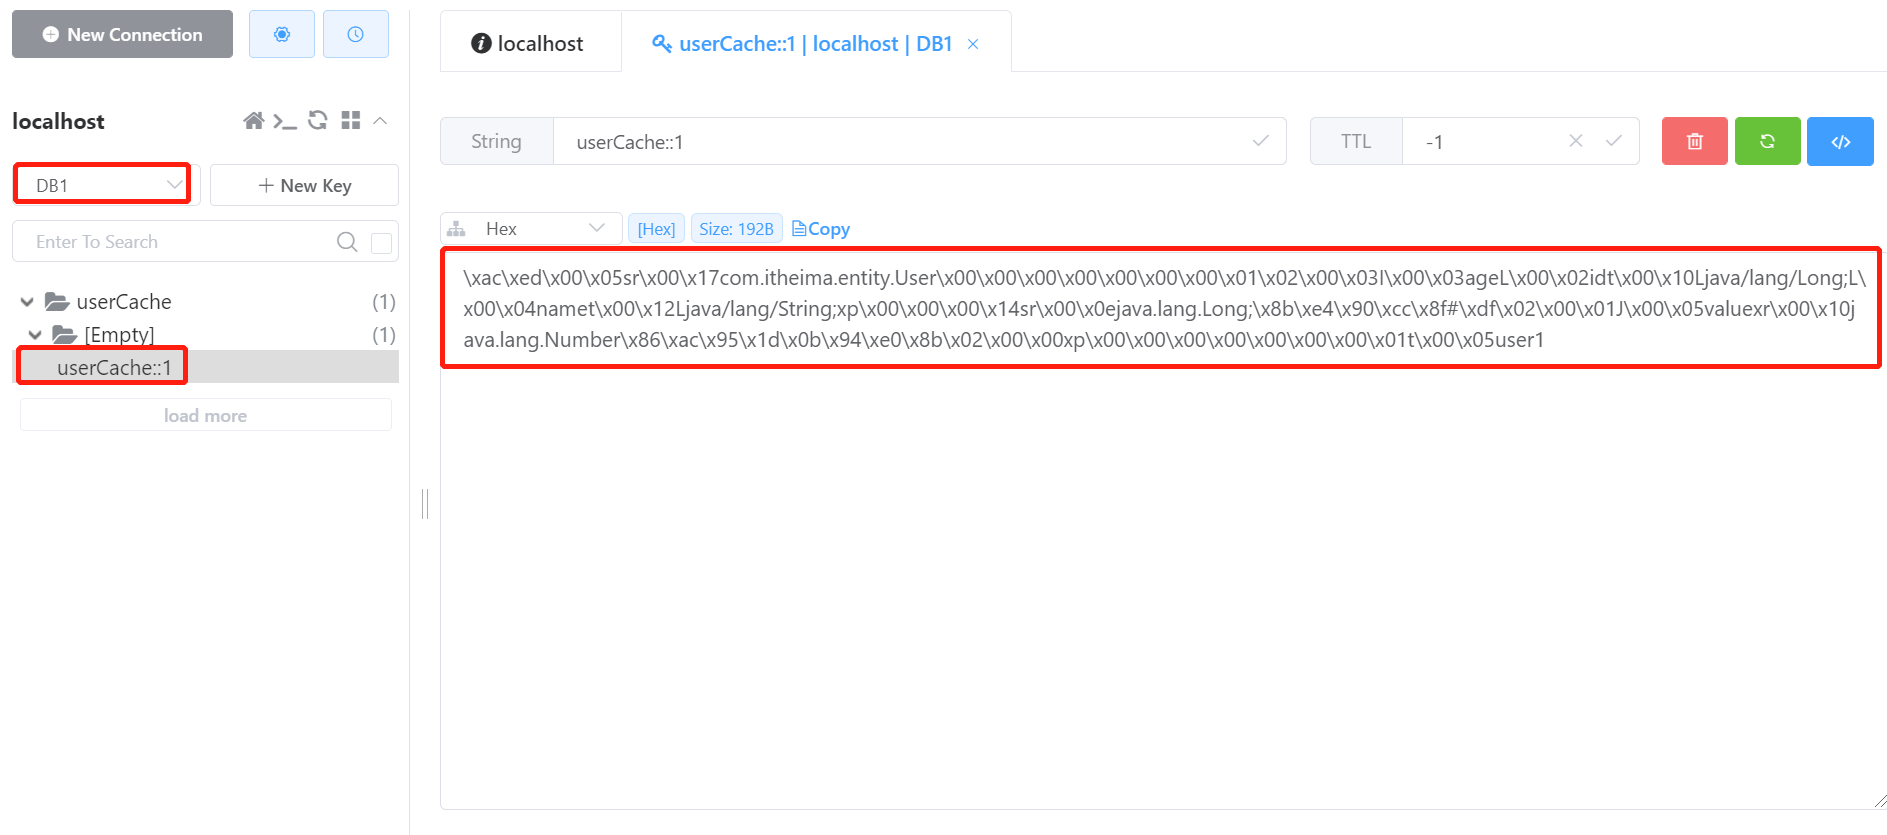 


**3). @Cacheable注解**

**@Cacheable 说明:**

 作用: 在方法执行前，spring先查看缓存中是否有数据，如果有数据，则直接返回缓存数据；若没有数据，调用方法并将方法返回值放到缓存中

 value: 缓存的名称，每个缓存名称下面可以有多个key

 key: 缓存的key  ----------> 支持Spring的表达式语言SPEL语法


 **在getById上加注解@Cacheable**

```java
	/**
	* Cacheable：在方法执行前spring先查看缓存中是否有数据，如果有数据，则直接返回缓存数据；若没有数据，	  *调用方法并将方法返回值放到缓存中
	* value：缓存的名称，每个缓存名称下面可以有多个key
	* key：缓存的key
	*/
	@GetMapping
    @Cacheable(cacheNames = "userCache",key="#id")
    public User getById(Long id){
        User user = userMapper.getById(id);
        return user;
    }
```

**重启服务,通过swagger接口文档测试，访问UserController的getById()方法**

第一次访问，会请求我们controller的方法，查询数据库。后面再查询相同的id，就直接从Redis中查询数据，不用再查询数据库了，就说明缓存生效了。

提前在redis中手动删除掉id=1的用户数据

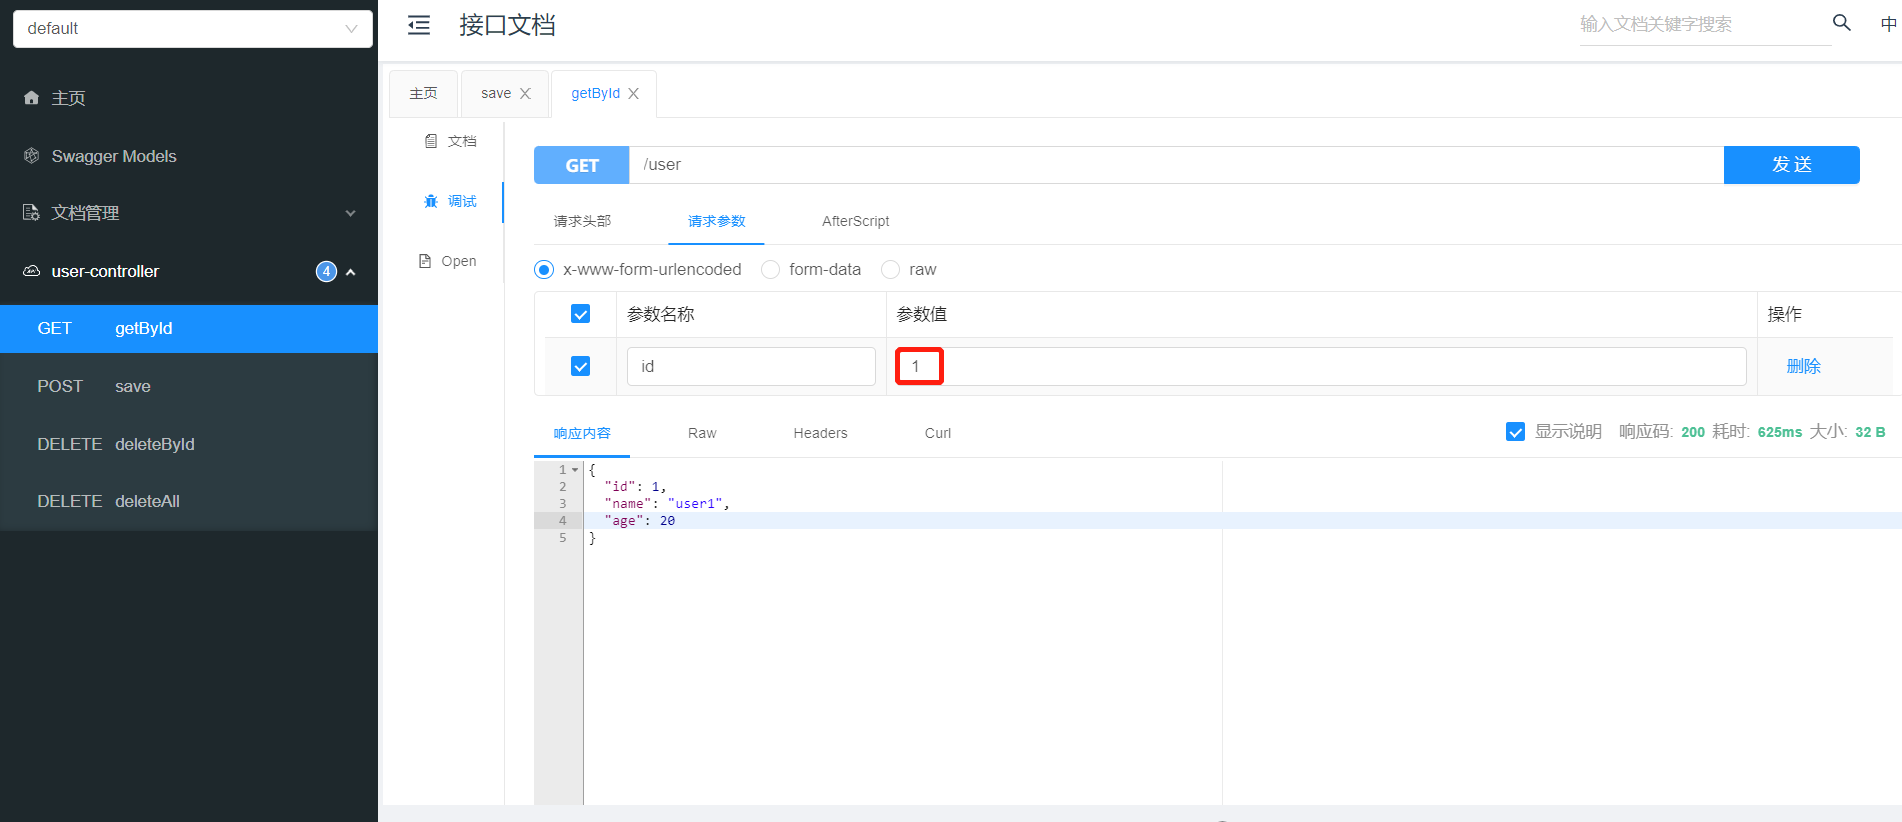 

**查看控制台sql语句：**说明从数据库查询的用户数据

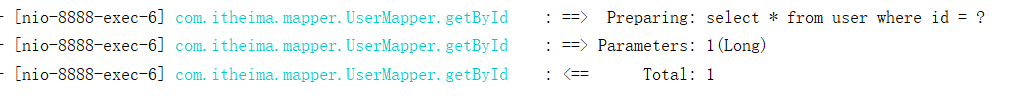 

**查看Redis中的缓存数据：**说明已成功缓存

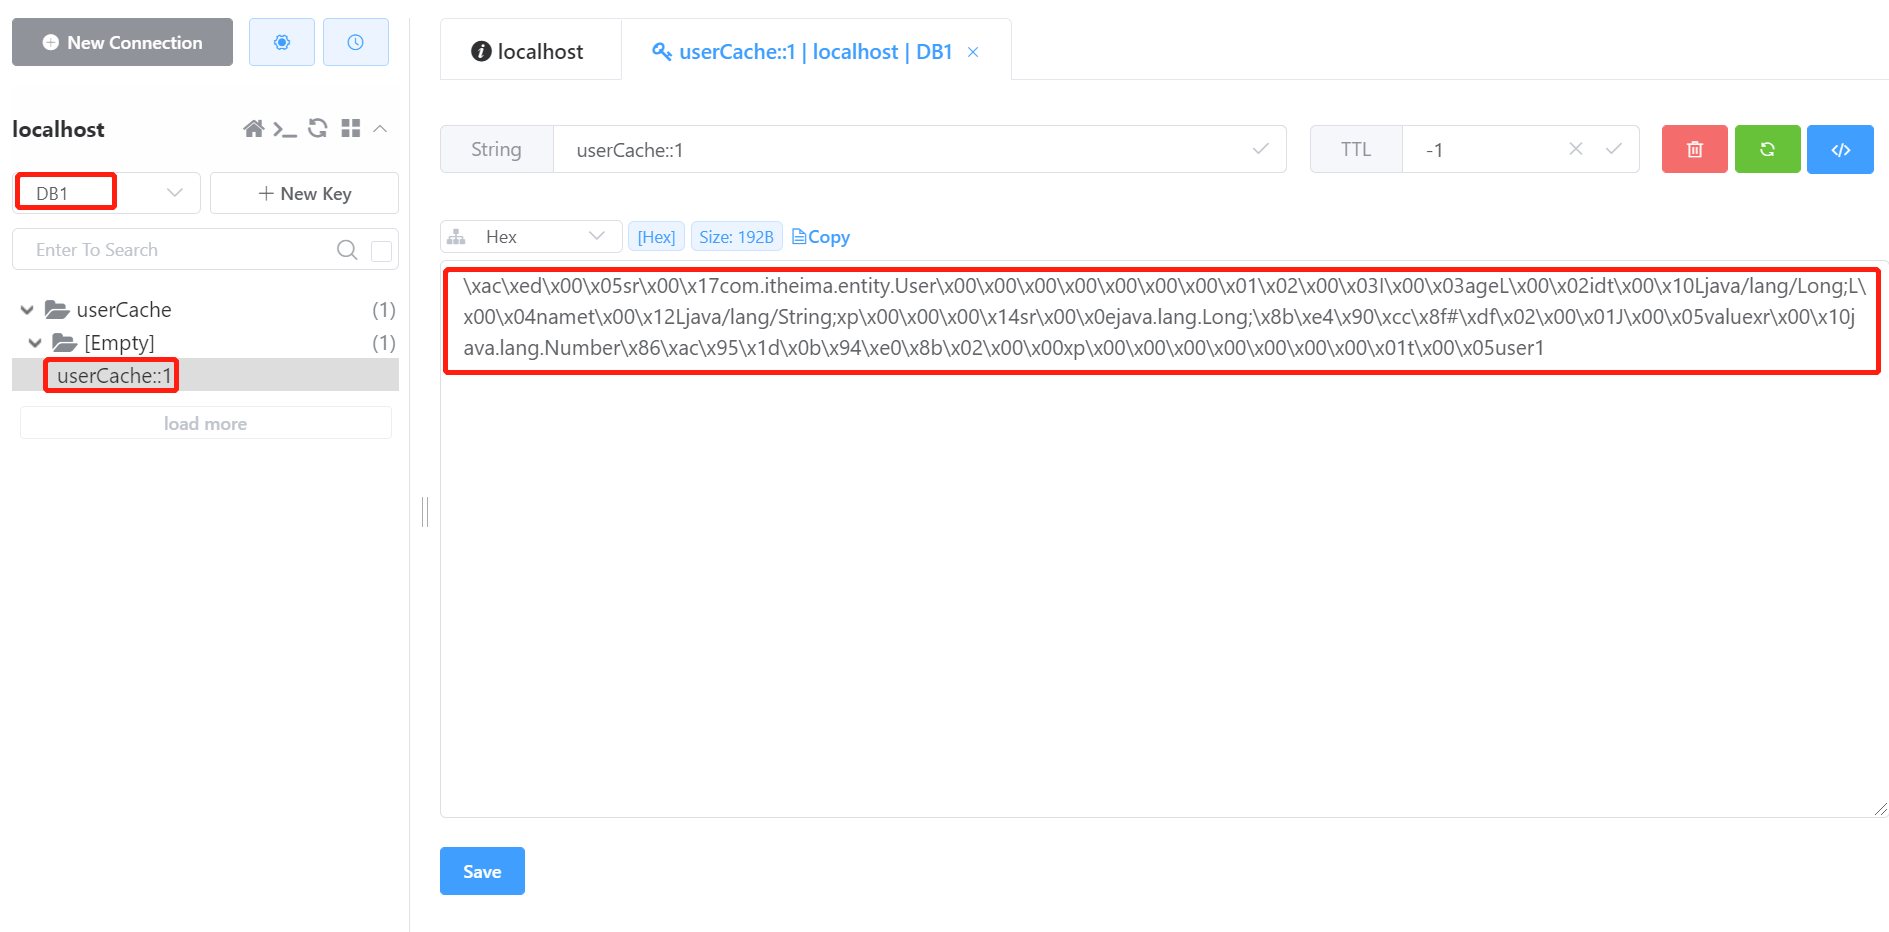 

再次查询相同id的数据时，直接从redis中直接获取，不再查询数据库。


**4). @CacheEvict注解**

**@CacheEvict 说明：** 

 作用: 清理指定缓存

 value: 缓存的名称，每个缓存名称下面可以有多个key

 key: 缓存的key  ----------> 支持Spring的表达式语言SPEL语法


**在 delete 方法上加注解@CacheEvict**

```java
	@DeleteMapping
    @CacheEvict(cacheNames = "userCache",key = "#id")//删除某个key对应的缓存数据
    public void deleteById(Long id){
        userMapper.deleteById(id);
    }

	@DeleteMapping("/delAll")
    @CacheEvict(cacheNames = "userCache",allEntries = true)//删除userCache下所有的缓存数据
    public void deleteAll(){
        userMapper.deleteAll();
    }
```

**重启服务,通过swagger接口文档测试，访问UserController的deleteAll()方法**

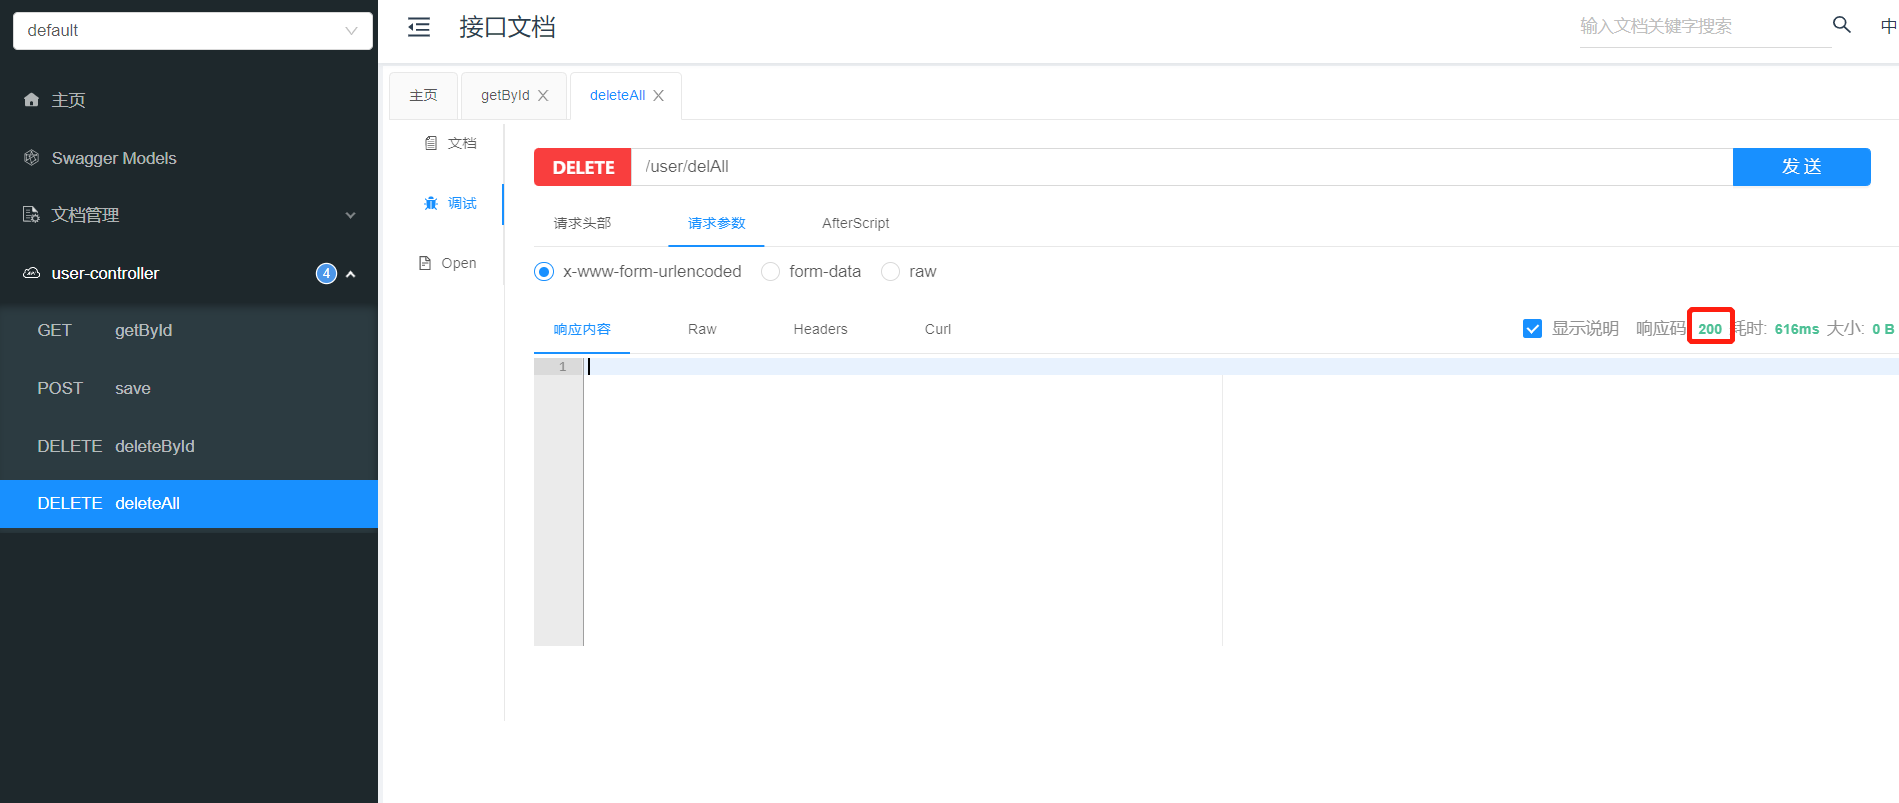 

**查看user表：**数据清空

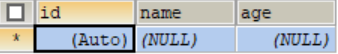 

**查询Redis缓存数据**

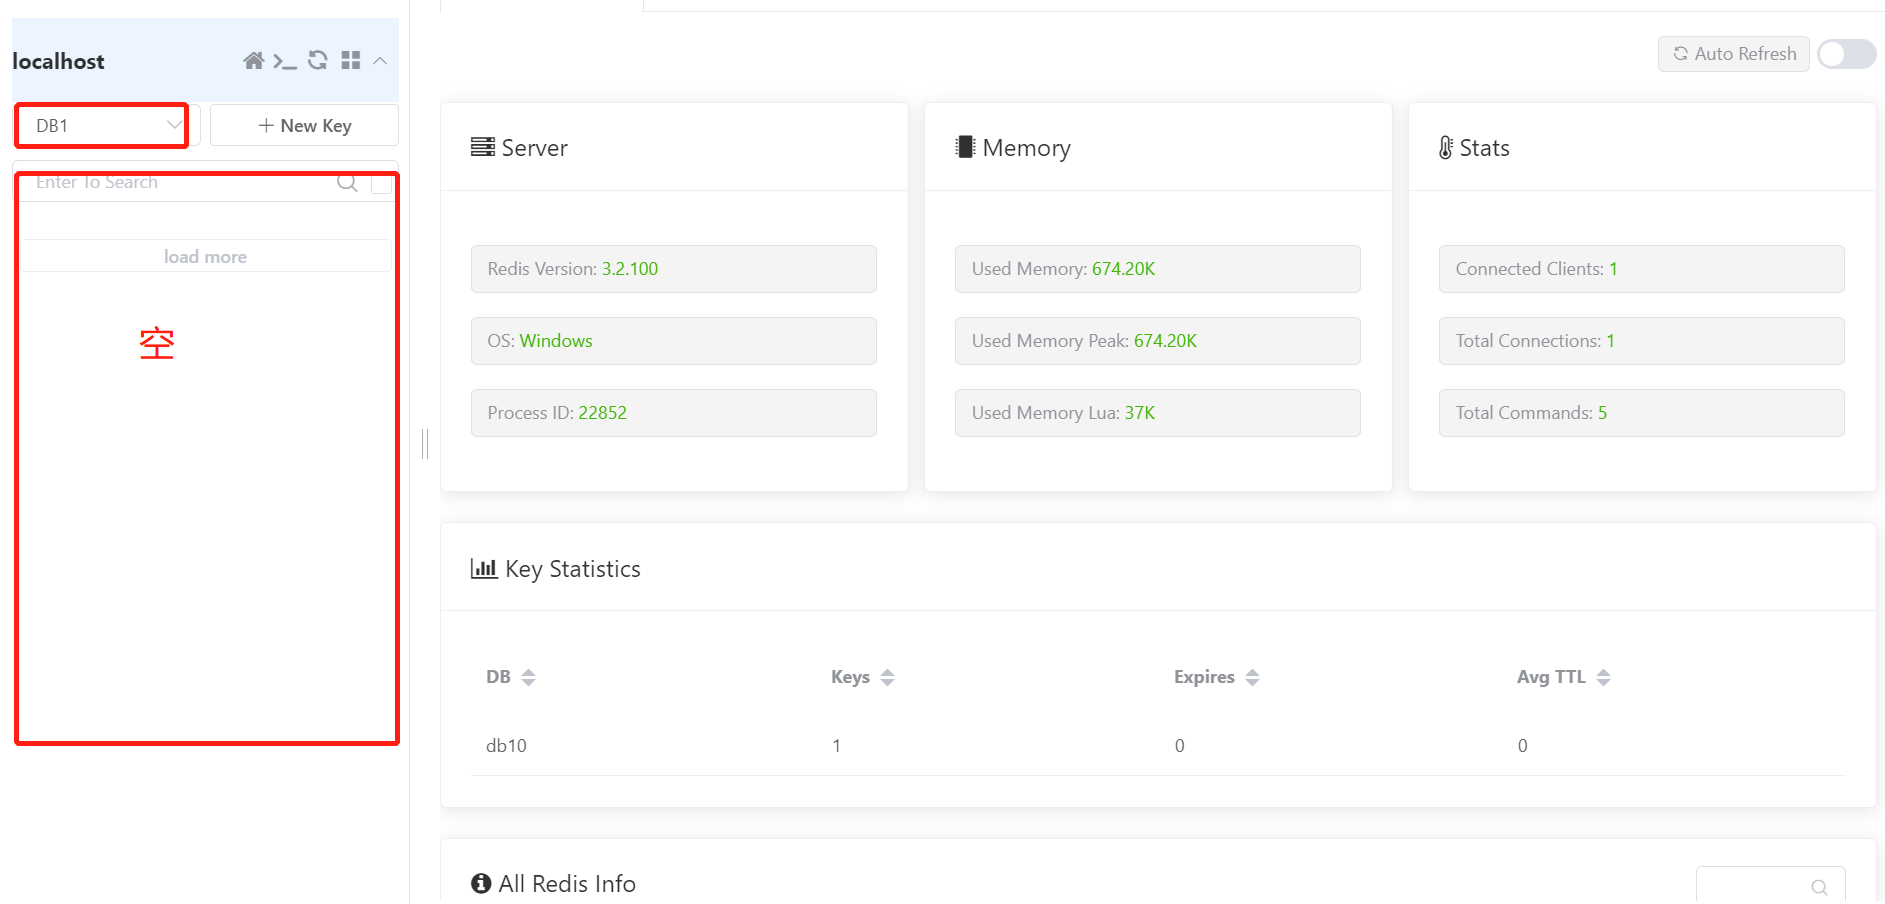


### 注解缓存的对象与执行时机（补充）

Spring Cache是一层缓存抽象，实际数据由CacheManager管理。@EnableCaching让Spring处理注解；底层是否Redis，要看生效的CacheManager，不是只看添加了某个注解或RedisTemplate。

| 注解 | 是否执行目标方法 | 缓存作用 |
| --- | --- | --- |
| Cacheable | 命中时通常不执行，未命中执行 | 缓存方法返回值 |
| CachePut | 每次执行 | 用返回值更新指定缓存 |
| CacheEvict | 正常执行目标方法 | 默认成功返回后删除指定缓存 |

原CacheDemo是单独的spring_cache_demo数据库与演示工程。它的UserController和deleteAll仅用于演示，不应导入苍穹外卖的微信用户模块，更不应对业务user表进行deleteAll跟练。

#### key表达式与返回值

cacheNames和value表示缓存名称；key是该名称下的条目。默认Redis前缀组成 `userCache::1`之类的key，但前缀可配置。

`#user.id`依赖可发现的方法参数名；`#p0.id`、`#a0.id`按参数位置取值更稳定。`#result`代表方法返回值，在CachePut等方法执行后的场景可以使用；Cacheable查缓存前还没有返回值，不能照搬`#result`当作它的查询key。

自动生成主键的save需要Mapper回填id，执行结束后才能用这个id缓存。CachePut缓存的是返回User，不是入参自动变成返回对象；void方法不适合照搬该示例。

CacheEvict默认beforeInvocation=false，方法抛异常通常不清理；如果只是返回错误Result，仍属于正常返回，清理可能照常执行。allEntries=true清理当前缓存名称下的条目，不表示清空整个Redis库，也不会自动删除MySQL表数据。

#### Spring代理与版本

缓存注解通常通过Spring代理生效。直接new对象或同类内部自调用，不能期待按普通代理方式命中缓存。放在Controller上也要有相应代理，不是Java原生语法本身完成缓存。

原入门依赖写2.7.3，业务工程已使用Boot依赖管理时通常不必重复锁定starter版本。示例版本应与工程一致，不为缓存单独混入另一套Boot依赖。


### 2.2 实现思路

> **PPT对照：** 第25页。

**实现步骤：**

1). 导入Spring Cache和Redis相关maven坐标

2). 在启动类上加入@EnableCaching注解，开启缓存注解功能

3). 在用户端接口SetmealController的 list 方法上加入@Cacheable注解

4). 在管理端接口SetmealController的 save、delete、update、startOrStop等方法上加入CacheEvict注解


### 套餐缓存与手动菜品缓存对照（补充）

| 方面 | 菜品手动缓存 | 套餐Spring Cache |
| --- | --- | --- |
| 读取代码 | RedisTemplate.get后判断 | Cacheable在方法调用前处理 |
| key | dish_分类id | setmealCache与分类id组合 |
| 缓存内容 | List<DishVO> | 当前Controller的Result<List<Setmeal>> |
| 写操作失效 | 显式delete/cleanCache | CacheEvict |
| TTL配置 | 每次set带期限或统一封装 | RedisCacheManager配置 |

原套餐list返回Result，所以注解缓存的是整个Result，包含data列表，不是只缓存局部变量list。若以后把注解移到Service，缓存对象可能变成List，需要同步考虑已有缓存格式。

这里的商品列表不随用户变化，可按分类共享。用户鉴权仍在Controller调用前由拦截器完成；不要把同样key策略套到购物车等个人数据上。


### 2.3 代码开发

> **PPT对照：** 第27—28页，修改与启停售代码由讲义展开。

按照上述实现步骤：

**1). 导入Spring Cache和Redis相关maven坐标(已实现)**

```xml
<dependency>
      <groupId>org.springframework.boot</groupId>
      <artifactId>spring-boot-starter-data-redis</artifactId>
</dependency>

<dependency>
      <groupId>org.springframework.boot</groupId>
      <artifactId>spring-boot-starter-cache</artifactId>
</dependency>
```


**2). 在启动类上加入@EnableCaching注解，开启缓存注解功能**

```java
package com.sky;

import lombok.extern.slf4j.Slf4j;
import org.springframework.boot.SpringApplication;
import org.springframework.boot.autoconfigure.SpringBootApplication;
import org.springframework.cache.annotation.EnableCaching;
import org.springframework.transaction.annotation.EnableTransactionManagement;

@SpringBootApplication
@EnableTransactionManagement //开启注解方式的事务管理
@Slf4j
@EnableCaching
public class SkyApplication {
    public static void main(String[] args) {
        SpringApplication.run(SkyApplication.class, args);
        log.info("server started");
    }
}
```


**3). 在用户端接口SetmealController的 list 方法上加入@Cacheable注解**

```java
	/**
     * 条件查询
     *
     * @param categoryId
     * @return
     */
    @GetMapping("/list")
    @ApiOperation("根据分类id查询套餐")
    @Cacheable(cacheNames = "setmealCache",key = "#categoryId") //key: setmealCache::100
    public Result<List<Setmeal>> list(Long categoryId) {
        Setmeal setmeal = new Setmeal();
        setmeal.setCategoryId(categoryId);
        setmeal.setStatus(StatusConstant.ENABLE);

        List<Setmeal> list = setmealService.list(setmeal);
        return Result.success(list);
    }
```


**4). 在管理端接口SetmealController的 save、delete、update、startOrStop等方法上加入CacheEvict注解**

```java
	/**
     * 新增套餐
     *
     * @param setmealDTO
     * @return
     */
    @PostMapping
    @ApiOperation("新增套餐")
    @CacheEvict(cacheNames = "setmealCache",key = "#setmealDTO.categoryId")//key: setmealCache::100
    public Result save(@RequestBody SetmealDTO setmealDTO) {
        setmealService.saveWithDish(setmealDTO);
        return Result.success();
    }
	/**
     * 批量删除套餐
     *
     * @param ids
     * @return
     */
    @DeleteMapping
    @ApiOperation("批量删除套餐")
    @CacheEvict(cacheNames = "setmealCache",allEntries = true)
    public Result delete(@RequestParam List<Long> ids) {
        setmealService.deleteBatch(ids);
        return Result.success();
    }
	/**
     * 修改套餐
     *
     * @param setmealDTO
     * @return
     */
    @PutMapping
    @ApiOperation("修改套餐")
    @CacheEvict(cacheNames = "setmealCache",allEntries = true)
    public Result update(@RequestBody SetmealDTO setmealDTO) {
        setmealService.update(setmealDTO);
        return Result.success();
    }

    /**
     * 套餐起售停售
     *
     * @param status
     * @param id
     * @return
     */
    @PostMapping("/status/{status}")
    @ApiOperation("套餐起售停售")
    @CacheEvict(cacheNames = "setmealCache",allEntries = true)
    public Result startOrStop(@PathVariable Integer status, Long id) {
        setmealService.startOrStop(status, id);
        return Result.success();
    }
```


### CacheManager、空key与失效范围（补充与勘误）

#### 1. RedisTemplate配置不等于RedisCacheManager配置

Spring Boot在相应依赖与条件满足时可自动装配RedisCacheManager；自定义CacheManager或其他缓存实现存在时，实际选择可能不同。第05章对RedisTemplate设置的序列化器，不会自动成为Spring Cache的全部配置。

默认Redis缓存一般没有到期时间，按实际工程配置验证。需要明确设置时，可在没有重复CacheManager定义的前提下新增或调整配置：

```java
@org.springframework.context.annotation.Bean
public org.springframework.data.redis.cache.RedisCacheManager cacheManager(
        org.springframework.data.redis.connection.RedisConnectionFactory factory) {
    org.springframework.data.redis.cache.RedisCacheConfiguration defaults =
            org.springframework.data.redis.cache.RedisCacheConfiguration
                    .defaultCacheConfig()
                    .entryTtl(java.time.Duration.ofMinutes(10));
    return org.springframework.data.redis.cache.RedisCacheManager.builder(factory)
            .cacheDefaults(defaults)
            .transactionAware()
            .build();
}
```

10分钟是本补充示例，默认序列化仍需适配Result与Setmeal对象。transactionAware使相关缓存操作可感知Spring事务提交，但不是MySQL与Redis的分布式事务，也不会消除缓存重建竞态。

#### 2. categoryId要明确必填与有效

原key="#categoryId"依赖参数名；请求不传categoryId时也可能生成null key错误。按分类列表接口约定，可用显式RequestParam并采用位置表达式：

```java
@GetMapping("/list")
@Cacheable(cacheNames = "setmealCache", key = "#p0",
        condition = "#p0 != null and #p0 > 0")
public Result<List<Setmeal>> list(@RequestParam("categoryId") Long categoryId) {
    // 先校验正整数分类id，再沿用原查询起售套餐及Result.success逻辑。
}
```

这是签名与注解替换示意，不是完整方法体。condition只决定是否缓存，不替代参数校验。与手动菜品缓存不同，原套餐方法正常返回一个非null Result，空data列表也通常会被缓存。

#### 3. 写接口的缓存名称要一致

新增清除本分类key，修改、删除、启停售清理setmealCache全部条目。若改成精确失效，跨分类修改需要同时清理旧、新分类；只用新DTO的categoryId不够。

读取与清理的cacheNames、key表达式和参数类型应一致。allEntries只清理套餐缓存区域，不清理dish_*或SHOP_STATUS；底层大规模清理是否使用KEYS还是SCAN取决于CacheWriter配置，注解本身不保证清理无阻塞。

Cacheable命中后方法体不执行，所以方法体内部的日志或校验也不会执行。需要每次请求都进行的鉴权、参数绑定与可见性约束，应放在合适的前置层，并在相关状态变化时正确失效。


### 2.4 功能测试

> **PPT对照：** 第30页。

通过前后端联调方式来进行测试，同时观察redis中缓存的套餐数据。和**缓存菜品**功能测试基本一致，不再赘述。


### 套餐缓存验收（补充）

先确认实际CacheManager类型和Redis数据库，首次查询生成setmealCache::分类id，第二次相同分类不再查套餐SQL。核对缓存对象的序列化格式以及设置后的TTL。

分别测试新增、修改价格、跨分类移动、删除和启停售。失败业务不应被误判为成功修改；写操作成功后，下一次读取应按预期重新查询。若注解未生效，检查EnableCaching、代理调用、key表达式及缓存名称，不只检查RedisTemplate是否注入。


### 2.5 代码提交

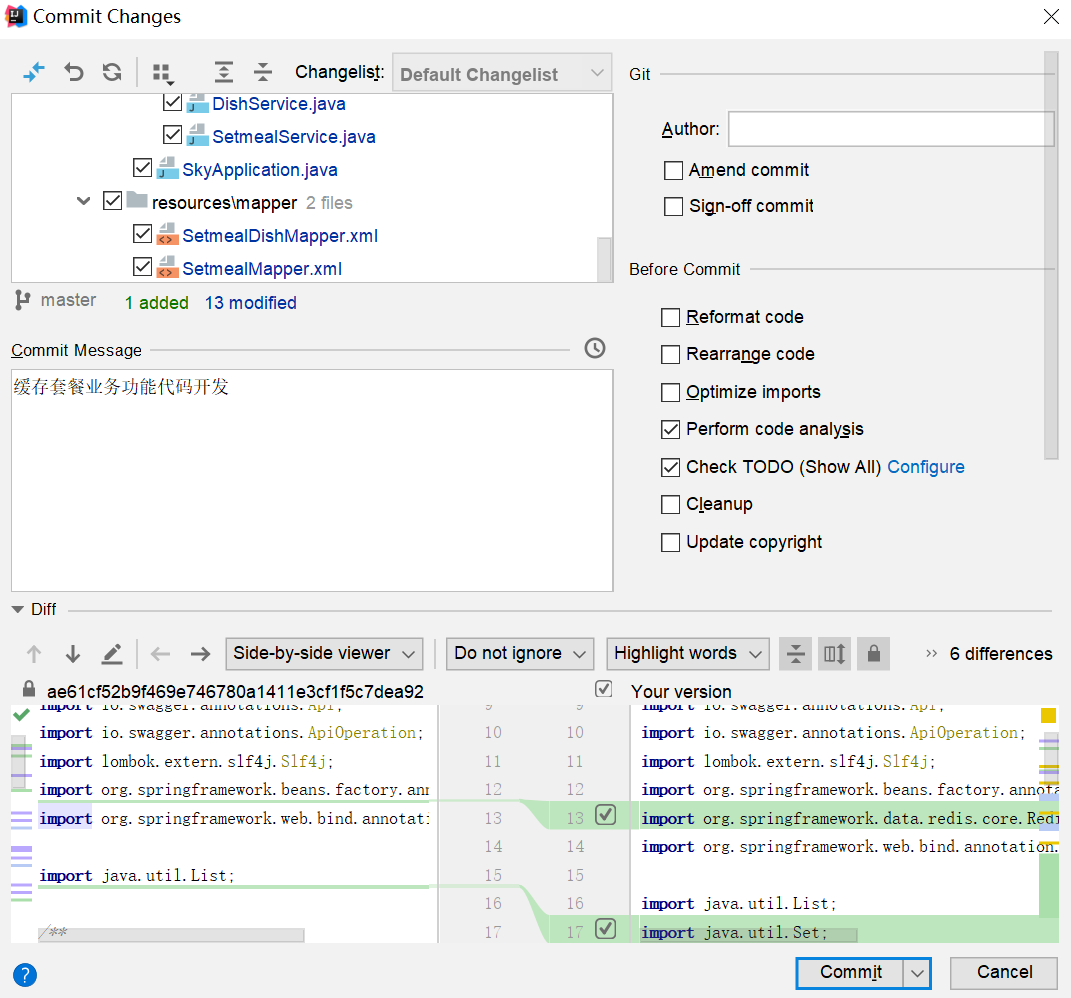 

后续步骤和其它功能代码提交一致，不再赘述。


## 3. 添加购物车

> **PPT对照：** 第32—48页。


### 3.1 需求分析和设计

> **PPT对照：** 第33—38页。

#### 3.1.1 产品原型

用户可以将菜品或者套餐添加到购物车。对于菜品来说，如果设置了口味信息，则需要选择规格后才能加入购物车;对于套餐来说，可以直接点击将当前套餐加入购物车。在购物车中可以修改菜品和套餐的数量，也可以清空购物车。

**效果图：**

 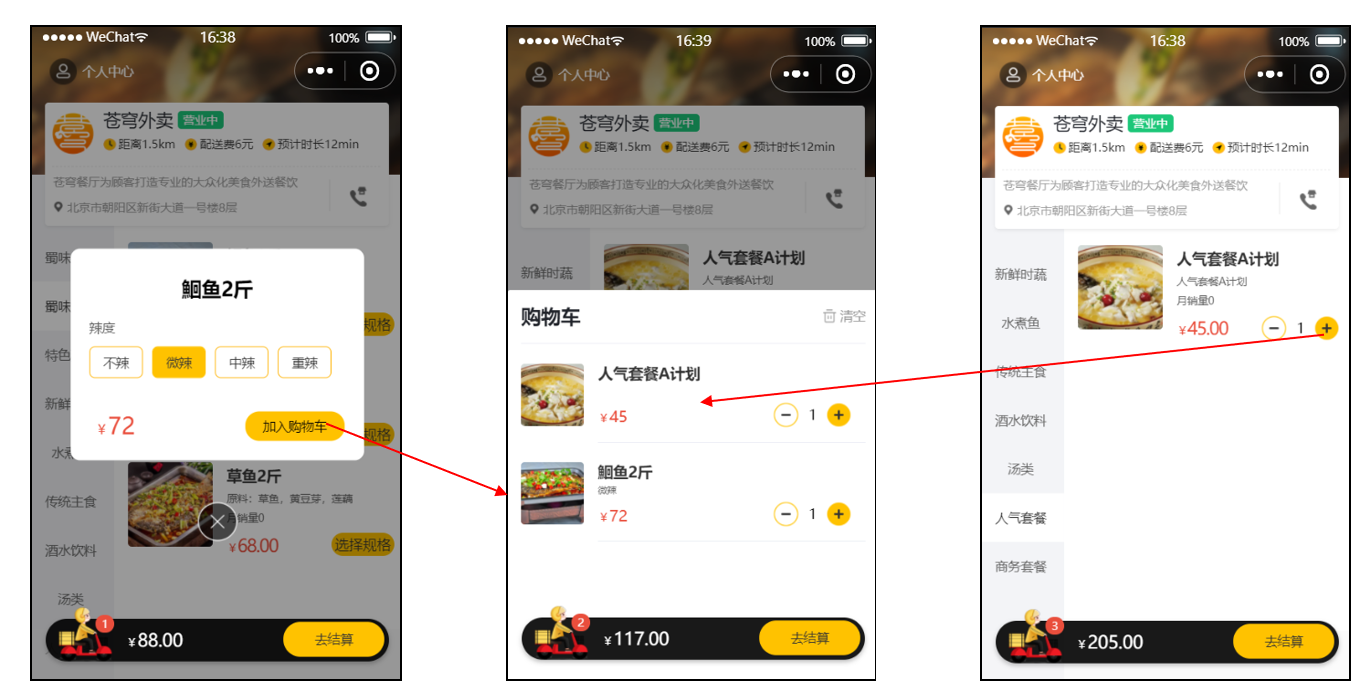 


#### 3.1.2 接口设计

通过上述原型图，设计出对应的添加购物车接口。

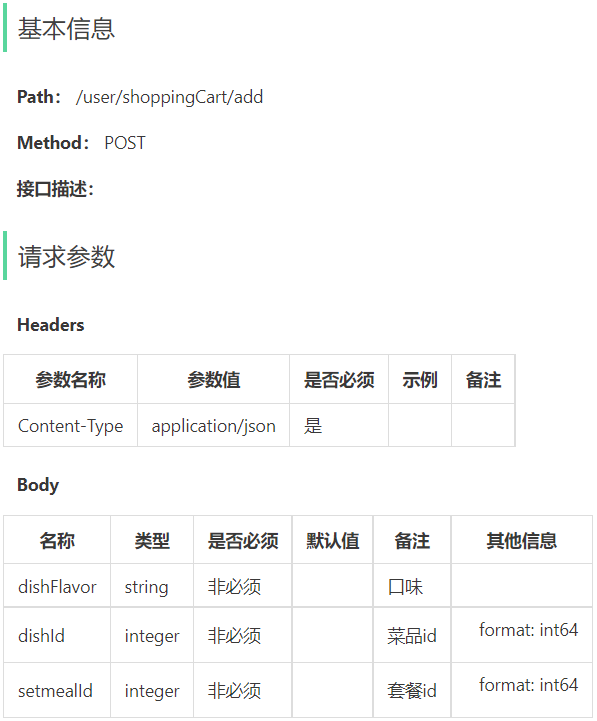 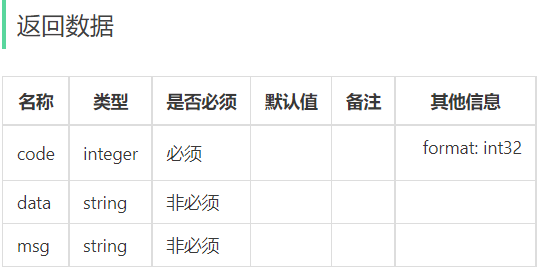

**说明：**添加购物车时，有可能添加菜品，也有可能添加套餐。故传入参数要么是菜品id，要么是套餐id。


#### 3.1.3 表设计

用户的购物车数据，也是需要保存在数据库中的，购物车对应的数据表为shopping_cart表，具体表结构如下：

| **字段名**  | **数据类型**  | **说明**     | **备注** |
| ----------- | ------------- | ------------ | -------- |
| id          | bigint        | 主键         | 自增     |
| name        | varchar(32)   | 商品名称     | 冗余字段 |
| image       | varchar(255)  | 商品图片路径 | 冗余字段 |
| user_id     | bigint        | 用户id       | 逻辑外键 |
| dish_id     | bigint        | 菜品id       | 逻辑外键 |
| setmeal_id  | bigint        | 套餐id       | 逻辑外键 |
| dish_flavor | varchar(50)   | 菜品口味     |          |
| number      | int           | 商品数量     |          |
| amount      | decimal(10,2) | 商品单价     | 冗余字段 |
| create_time | datetime      | 创建时间     |          |

**说明：** 

- 购物车数据是关联用户的，在表结构中，我们需要记录，每一个用户的购物车数据是哪些
- 菜品列表展示出来的既有套餐，又有菜品，如果用户选择的是套餐，就保存套餐ID(setmeal_id)，如果用户选择的是菜品，就保存菜品ID(dish_id)
- 对同一个菜品/套餐，如果选择多份不需要添加多条记录，增加数量number即可


### 购物车一行代表什么（补充）

同一用户、同一种商品、同一组规格是一行，number记录数量。相同菜品但不同口味应分行；套餐不使用菜品口味。不同用户即使选择完全相同的商品，也必须保存不同的购物车行。

| 字段 | 由谁决定 |
| --- | --- |
| dishId / setmealId | 客户端选择商品，后端验证二选一和合法性 |
| dishFlavor | 客户端选规格，后端验证并规范化 |
| userId | 用户拦截器与BaseContext，不能信任客户端 |
| name / image / amount | 后端从菜品或套餐记录读取 |
| number | 原add接口每次增加1，不接受任意数量入参 |
| createTime | 后端生成首次添加时间 |

amount是商品单价，不是该行合计。行金额为amount×number，购物车合计为各行求和，用BigDecimal计算。

名称、图片和价格是方便展示的冗余快照。原重复添加只改number，不自动刷新旧单价；后续下单必须重新检查商品是否可售、价格和规格，不把购物车快照当作最终交易依据。


### 3.2 代码开发

> **PPT对照：** 第40—46页。

#### 3.2.1 DTO设计

**根据添加购物车接口的参数设计DTO：**

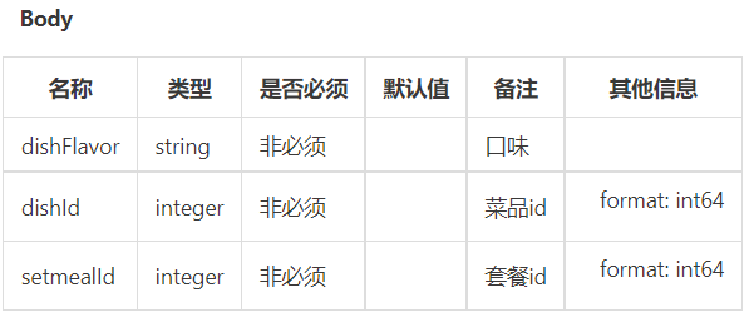 

在sky-pojo模块，ShoppingCartDTO.java已定义

```java
package com.sky.dto;

import lombok.Data;
import java.io.Serializable;

@Data
public class ShoppingCartDTO implements Serializable {

    private Long dishId;
    private Long setmealId;
    private String dishFlavor;

}
```


#### 3.2.2 Controller层

**根据添加购物车接口创建ShoppingCartController：**

```java
package com.sky.controller.user;


import com.sky.dto.ShoppingCartDTO;
import com.sky.result.Result;
import io.swagger.annotations.Api;
import io.swagger.annotations.ApiOperation;
import lombok.extern.slf4j.Slf4j;
import org.springframework.beans.factory.annotation.Autowired;
import org.springframework.web.bind.annotation.PostMapping;
import org.springframework.web.bind.annotation.RequestBody;
import org.springframework.web.bind.annotation.RequestMapping;
import org.springframework.web.bind.annotation.RestController;

/**
 * 购物车
 */
@RestController
@RequestMapping("/user/shoppingCart")
@Slf4j
@Api(tags = "C端-购物车接口")
public class ShoppingCartController {

    @Autowired
    private ShoppingCartService shoppingCartService;

    /**
     * 添加购物车
     * @param shoppingCartDTO
     * @return
     */
    @PostMapping("/add")
    @ApiOperation("添加购物车")
    public Result<String> add(@RequestBody ShoppingCartDTO shoppingCartDTO){
        log.info("添加购物车：{}", shoppingCartDTO);
        shoppingCartService.addShoppingCart(shoppingCartDTO);//后绪步骤实现
        return Result.success();
    }
}
```


#### 3.2.3 Service层接口

**创建ShoppingCartService接口：**

```java
package com.sky.service;

import com.sky.dto.ShoppingCartDTO;
import com.sky.entity.ShoppingCart;
import java.util.List;

public interface ShoppingCartService {

    /**
     * 添加购物车
     * @param shoppingCartDTO
     */
    void addShoppingCart(ShoppingCartDTO shoppingCartDTO);
}
```


#### 3.2.4 Service层实现类

**创建ShoppingCartServiceImpl实现类，并实现add方法：**

```java
package com.sky.service.impl;


import com.sky.context.BaseContext;
import com.sky.dto.ShoppingCartDTO;
import com.sky.entity.Dish;
import com.sky.entity.Setmeal;
import com.sky.entity.ShoppingCart;
import com.sky.mapper.DishMapper;
import com.sky.mapper.SetmealMapper;
import com.sky.service.ShoppingCartService;
import org.springframework.beans.BeanUtils;
import org.springframework.beans.factory.annotation.Autowired;
import org.springframework.stereotype.Service;
import java.time.LocalDateTime;
import java.util.List;

@Service
public class ShoppingCartServiceImpl implements ShoppingCartService {

    @Autowired
    private ShoppingCartMapper shoppingCartMapper;
    @Autowired
    private DishMapper dishMapper;
    @Autowired
    private SetmealMapper setmealMapper;
    
    /**
     * 添加购物车
     *
     * @param shoppingCartDTO
     */
    public void addShoppingCart(ShoppingCartDTO shoppingCartDTO) {
        ShoppingCart shoppingCart = new ShoppingCart();
        BeanUtils.copyProperties(shoppingCartDTO, shoppingCart);
        //只能查询自己的购物车数据
        shoppingCart.setUserId(BaseContext.getCurrentId());

        //判断当前商品是否在购物车中
        List<ShoppingCart> shoppingCartList = shoppingCartMapper.list(shoppingCart);

        if (shoppingCartList != null && shoppingCartList.size() == 1) {
            //如果已经存在，就更新数量，数量加1
            shoppingCart = shoppingCartList.get(0);
            shoppingCart.setNumber(shoppingCart.getNumber() + 1);
            shoppingCartMapper.updateNumberById(shoppingCart);
        } else {
            //如果不存在，插入数据，数量就是1

            //判断当前添加到购物车的是菜品还是套餐
            Long dishId = shoppingCartDTO.getDishId();
            if (dishId != null) {
                //添加到购物车的是菜品
                Dish dish = dishMapper.getById(dishId);
                shoppingCart.setName(dish.getName());
                shoppingCart.setImage(dish.getImage());
                shoppingCart.setAmount(dish.getPrice());
            } else {
                //添加到购物车的是套餐
                Setmeal setmeal = setmealMapper.getById(shoppingCartDTO.getSetmealId());
                shoppingCart.setName(setmeal.getName());
                shoppingCart.setImage(setmeal.getImage());
                shoppingCart.setAmount(setmeal.getPrice());
            }
            shoppingCart.setNumber(1);
            shoppingCart.setCreateTime(LocalDateTime.now());
            shoppingCartMapper.insert(shoppingCart);
        }
    }
}
```


#### 3.2.5 Mapper层

**创建ShoppingCartMapper接口:**

```java
package com.sky.mapper;

import com.sky.entity.ShoppingCart;
import org.apache.ibatis.annotations.Delete;
import org.apache.ibatis.annotations.Insert;
import org.apache.ibatis.annotations.Mapper;
import org.apache.ibatis.annotations.Update;
import java.util.List;

@Mapper
public interface ShoppingCartMapper {
    /**
     * 条件查询
     *
     * @param shoppingCart
     * @return
     */
    List<ShoppingCart> list(ShoppingCart shoppingCart);

    /**
     * 更新商品数量
     *
     * @param shoppingCart
     */
    @Update("update shopping_cart set number = #{number} where id = #{id}")
    void updateNumberById(ShoppingCart shoppingCart);

    /**
     * 插入购物车数据
     *
     * @param shoppingCart
     */
    @Insert("insert into shopping_cart (name, user_id, dish_id, setmeal_id, dish_flavor, number, amount, image, create_time) " +
            " values (#{name},#{userId},#{dishId},#{setmealId},#{dishFlavor},#{number},#{amount},#{image},#{createTime})")
    void insert(ShoppingCart shoppingCart);

}
```

**创建ShoppingCartMapper.xml：**

```xml
<?xml version="1.0" encoding="UTF-8" ?>
<!DOCTYPE mapper PUBLIC "-//mybatis.org//DTD Mapper 3.0//EN" "http://mybatis.org/dtd/mybatis-3-mapper.dtd" >
<mapper namespace="com.sky.mapper.ShoppingCartMapper">
    <select id="list" parameterType="ShoppingCart" resultType="ShoppingCart">
        select * from shopping_cart
        <where>
            <if test="userId != null">
                and user_id = #{userId}
            </if>
            <if test="dishId != null">
                and dish_id = #{dishId}
            </if>
            <if test="setmealId != null">
                and setmeal_id = #{setmealId}
            </if>
            <if test="dishFlavor != null">
                and dish_flavor = #{dishFlavor}
            </if>
        </where>
        order by create_time desc
    </select>
</mapper>
```


### 购物车匹配、身份与数量更新（补充与勘误）

#### 1. 原代码必须先校验的输入

dishId和setmealId必须有且仅有一个，id必须为有效正整数。两者都为空时，原查询可能变成“当前用户全部购物车”；两者都存在时，SQL要求同时匹配两个字段，随后代码又按菜品分支插入，语义不清。

商品不存在时，getById返回null，原代码紧接getName会空指针。前端只能点起售商品不等于后端可省略检查；直接调用add也需验证商品存在、起售状态，以及业务要求的分类和套餐可售条件。

BaseContext必须是本次用户JWT解析的user.id。若为null，原动态SQL会省略user_id条件，可能查到其他用户行。不能用随意固定userId掩盖鉴权遗漏；用户请求结束清理沿用第06章。

#### 2. null口味不是“不限制口味”

原list同时用于精确查找购物车行和查看全部购物车，因此dishFlavor为null时省略条件。对同一菜品存在“微辣”“中辣”行时，缺少口味的add会匹配到这些行：一条时加错规格，多条时反而走新增分支。

应区分“查当前用户所有行”和“查当前用户这一商品这一规格”。以下补充约定无规格统一为空字符串，兼容历史NULL；有规格字符串先按前后端约定规范化。仅trim不保证两组顺序不同的选项会变成同一个值，不能随意改变前端格式。

在已有ShoppingCartMapper添加专用方法：

```java
List<ShoppingCart> findItem(
        @org.apache.ibatis.annotations.Param("cart") ShoppingCart cart);
```

在现有ShoppingCartMapper.xml的mapper节点内增加查询，注意与原list区分statement id：

```xml
<select id="findItem" resultType="com.sky.entity.ShoppingCart">
    select * from shopping_cart
    where user_id = #{cart.userId}
    <choose>
        <when test="cart.dishId != null">
            and dish_id = #{cart.dishId}
            and setmeal_id is null
            and coalesce(dish_flavor, '') = #{cart.dishFlavor}
        </when>
        <otherwise>
            and setmeal_id = #{cart.setmealId}
            and dish_id is null
            and coalesce(dish_flavor, '') = ''
        </otherwise>
    </choose>
</select>
```

user_id是强制条件，不放在可省略的if里。Service仍要验证用户id和商品二选一；这里的otherwise不能代替校验。COALESCE用于兼容旧无规格NULL，但可能影响索引利用；完成规范化与迁移后可按一致存储规则改为直接等值比较。

#### 3. 数量增加使用数据库原子加一

原“读number → Java加1 → set number”在并发下可能两次都读到1，最终都写2，少记一份。针对已有购物车行，可新增以下方法，在SQL里执行加一，并同时限定所属用户：

```java
@org.apache.ibatis.annotations.Update(
    "update shopping_cart set number = number + 1 " +
    "where id = #{id} and user_id = #{userId} " +
    "and number >= 1 and number < 2147483647")
int incrementNumber(
    @org.apache.ibatis.annotations.Param("id") Long id,
    @org.apache.ibatis.annotations.Param("userId") Long userId);
```

2147483647是int上限，实际购买数量上限应按业务另行设定。检查影响行数为1，避免已被清空或数量异常时仍返回成功。原updateNumberById若还用于其他数量修改，同样应验证userId和范围。

#### 4. Service修正示例

以下替换原addShoppingCart，使用刚增加的findItem/incrementNumber和已有insert。保留原已注入的三个Mapper与BeanUtils，添加requireCurrentUserId辅助方法；异常接入现有统一处理器。

```java
private Long requireCurrentUserId() {
    Long userId = BaseContext.getCurrentId();
    if (userId == null || userId <= 0) {
        throw new IllegalStateException("缺少当前登录用户");
    }
    return userId;
}

@Override
@org.springframework.transaction.annotation.Transactional(rollbackFor = Exception.class)
public void addShoppingCart(ShoppingCartDTO dto) {
    Long userId = requireCurrentUserId();
    if (dto == null) {
        throw new IllegalArgumentException("购物车参数不能为空");
    }
    boolean isDish = dto.getDishId() != null;
    boolean isSetmeal = dto.getSetmealId() != null;
    if (isDish == isSetmeal) {
        throw new IllegalArgumentException("菜品和套餐必须二选一");
    }
    Long productId = isDish ? dto.getDishId() : dto.getSetmealId();
    if (productId <= 0) {
        throw new IllegalArgumentException("商品id不合法");
    }
    String flavor = dto.getDishFlavor() == null
            ? "" : dto.getDishFlavor().trim();
    if (!isDish && !flavor.isEmpty()) {
        throw new IllegalArgumentException("套餐不接收菜品口味");
    }
    if (flavor.length() > 50) {
        throw new IllegalArgumentException("口味内容过长");
    }

    ShoppingCart cart = new ShoppingCart();
    BeanUtils.copyProperties(dto, cart);
    cart.setUserId(userId);
    cart.setDishFlavor(flavor);

    // 从真实商品记录取价格、名称、图片，校验后才查购物车。
    if (isDish) {
        Dish dish = dishMapper.getById(productId);
        if (dish == null || !Integer.valueOf(1).equals(dish.getStatus())) {
            throw new IllegalArgumentException("菜品不存在或已停售");
        }
        // 有口味菜品还需校验必选项、实际选项与规范化规则。
        cart.setName(dish.getName());
        cart.setImage(dish.getImage());
        cart.setAmount(dish.getPrice());
    } else {
        Setmeal setmeal = setmealMapper.getById(productId);
        if (setmeal == null || !Integer.valueOf(1).equals(setmeal.getStatus())) {
            throw new IllegalArgumentException("套餐不存在或已停售");
        }
        cart.setName(setmeal.getName());
        cart.setImage(setmeal.getImage());
        cart.setAmount(setmeal.getPrice());
    }

    List<ShoppingCart> rows = shoppingCartMapper.findItem(cart);
    if (rows == null || rows.size() > 1) {
        throw new IllegalStateException("购物车匹配结果异常");
    }
    if (!rows.isEmpty()) {
        int affected = shoppingCartMapper.incrementNumber(rows.get(0).getId(), userId);
        if (affected != 1) {
            throw new IllegalStateException("购物车数量更新失败");
        }
        return;
    }

    cart.setNumber(1);
    cart.setCreateTime(LocalDateTime.now());
    shoppingCartMapper.insert(cart);
}
```

这个示例修正了身份缺失、商品二选一、空规格匹配、重复行和已有行加一。口味是否合法仍需结合实际dish_flavor选项及前端字符串约定实现，注释不表示已完成完整规格校验。

#### 5. 事务不自动解决首次重复插入

两个并发请求仍可能都查到无记录，然后各插一行。上述@Transactional和原子加一解决不了这一首次创建竞态；真实实现需要规范化的购物车项唯一标识、唯一约束及合适的原子插入/更新策略，或可靠锁定方案。

不能简单把user_id、dish_id、setmeal_id、dish_flavor组成唯一索引就声称完成：MySQL唯一索引允许多个NULL，两个互斥商品id和口味空值会影响保护。可按统一商品类型、商品id、规范化规格key设计唯一项，再清理历史重复行后迁移。

重复点击每次意味着add一份，原接口没有幂等键。网络超时后盲目重试可能增加两份，若业务要求精确重试，需要另定义请求幂等规则。

#### imports与已有依赖

原ShoppingCartController缺少ShoppingCartService import，原实现类缺ShoppingCartMapper import；随后添加查看与清空时，还需GetMapping、DeleteMapping、ShoppingCart和List等imports。实体ShoppingCart应已有对应字段与builder；SQL类型别名未配置时使用完整类名。

SetmealMapper.getById来自已有套餐管理，DishMapper.getById来自第03章。不要为补一个方法覆盖原Mapper；购物车只有createTime等字段，不套用第03章要求四个审计setter的AutoFill。


### 3.3 功能测试

> **PPT对照：** 第48页。

进入小程序，添加菜品

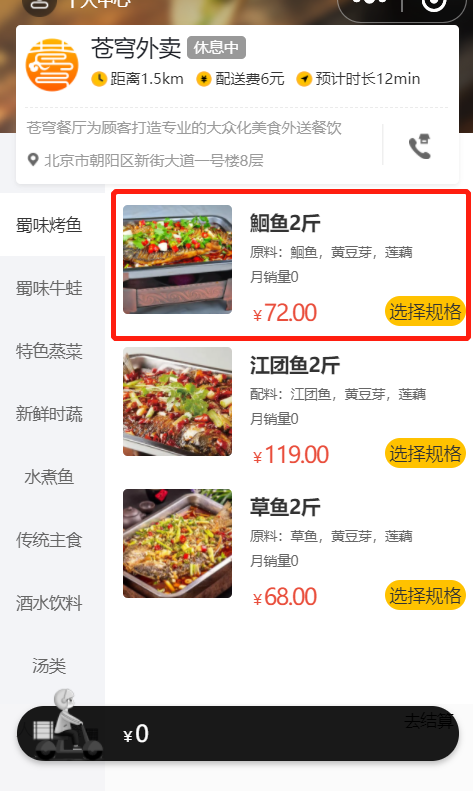 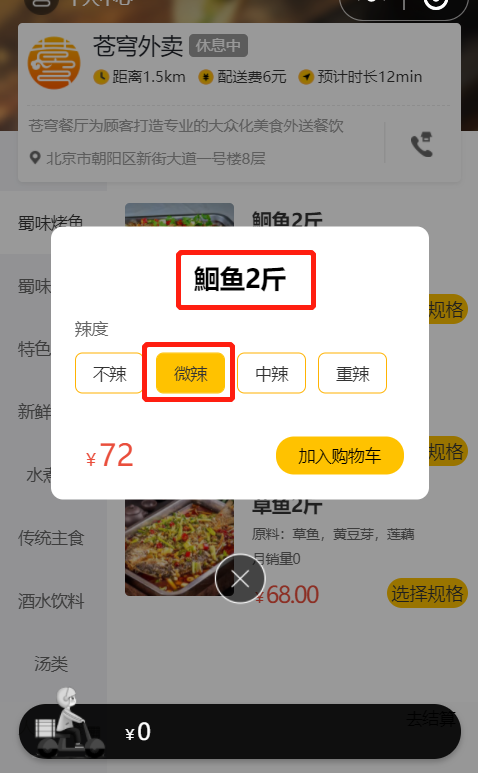

加入购物车，查询数据库

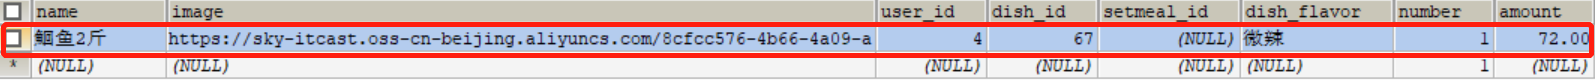 

因为现在没有实现查看购物车功能，所以只能在表中进行查看。

在前后联调时，后台可通断点方式启动，查看运行的每一步。


### 添加购物车验收（补充）

| 场景 | 预期结果 |
| --- | --- |
| 第一次添加菜品 | 新行number=1，userId正确，单价来自dish |
| 相同菜品相同规格再次添加 | 原行number+1，不新增行 |
| 相同菜品不同规格 | 分成两行，互不增加数量 |
| 无规格菜品再次添加 | 只匹配无规格行，不匹配其他口味 |
| 套餐首次、再次添加 | 同套餐数量增加，amount来自setmeal.price |
| 两个用户添加同商品 | 各自独立记录 |
| 两个id都传或都不传 | 拒绝，不发生模糊查询或插入 |
| 不存在、停售商品或无效规格 | 按规则拒绝，不发生空指针 |
| 匹配出多行 | 识别历史重复问题，不继续插新行 |
| 并发添加与清空 | 验证数量、重复行与实际并发策略 |

添加后查shopping_cart核对用户、商品、口味、number和amount。假设单价10、数量3，amount仍为10而不是30；购物车行合计另算。尚未实现查看接口时，页面是否显示不能替代数据库核对。


### 3.4 代码提交

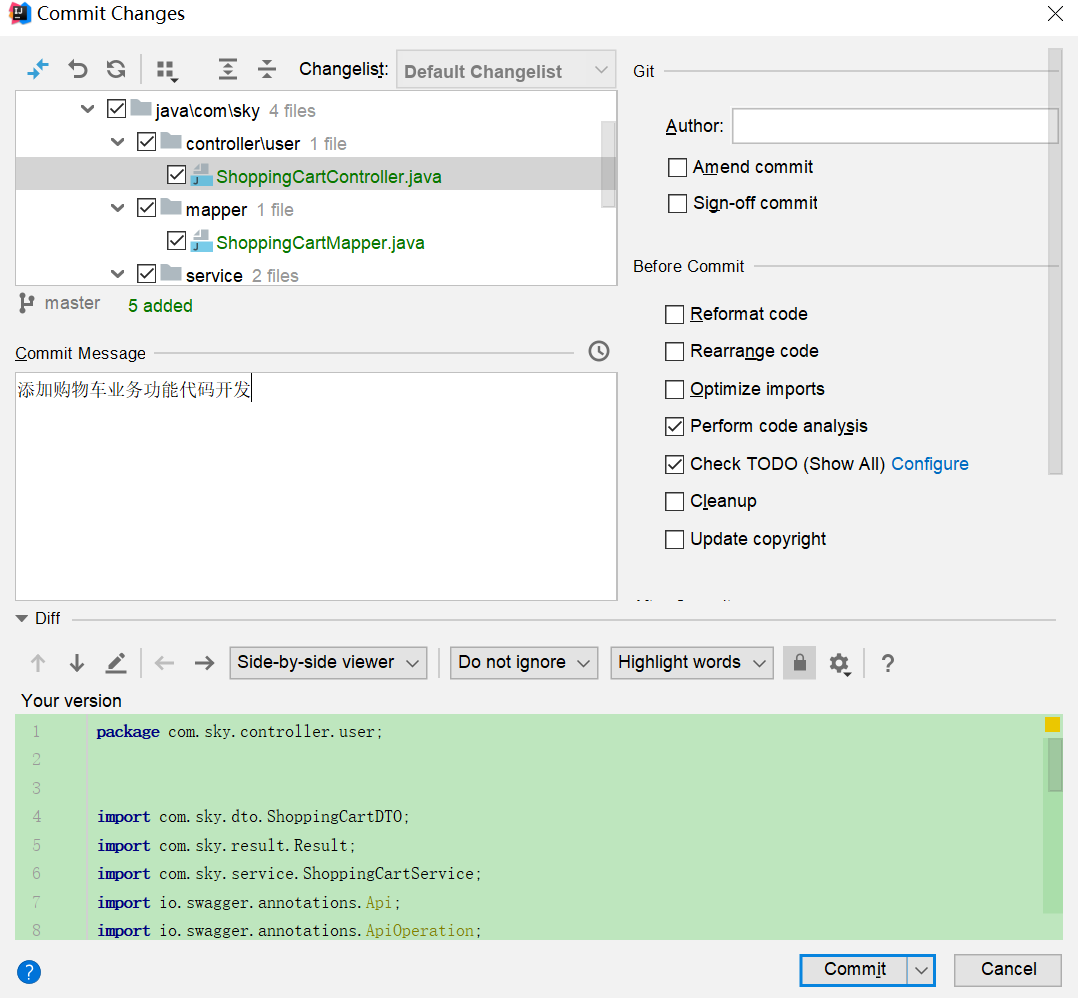 

后续步骤和其它功能代码提交一致，不再赘述。


## 4. 查看购物车

> **PPT对照：** 第50—58页。


### 4.1 需求分析和设计

> **PPT对照：** 第51—52页。

#### 4.1.1 产品原型

当用户添加完菜品和套餐后，可进入到购物车中，查看购物中的菜品和套餐。

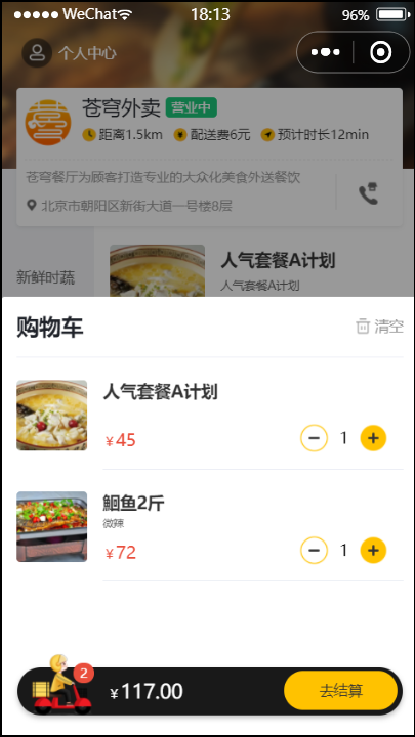 


#### 4.1.2 接口设计

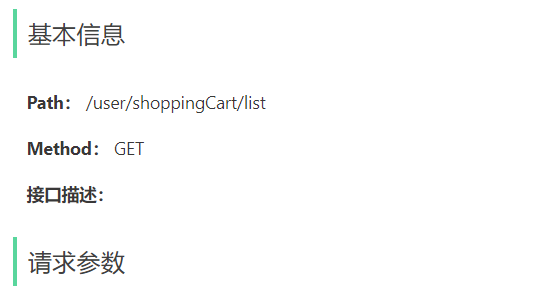 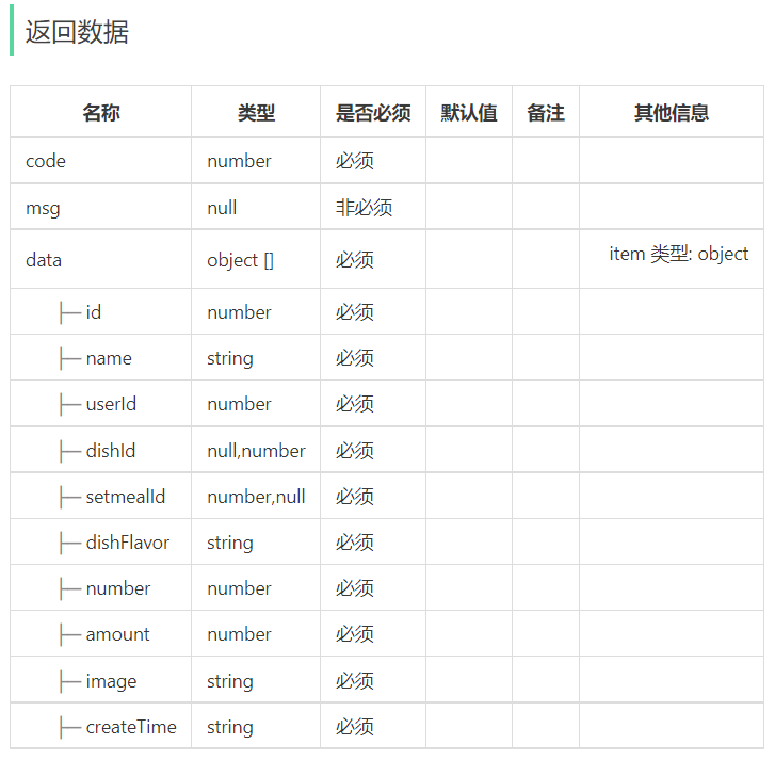


### 查看当前用户全部条目（补充）

查看接口没有userId入参，因为身份来自当前用户token。它返回全部购物车行，包括菜品、套餐和各规格；这里不应带“指定商品的口味条件”。

这与添加时精确找同一购物车项是不同用途，所以补充的findItem和原list分开。无购物车时正常返回空列表，页面显示空状态，而不是请求其他用户的数据填充界面。


### 4.2 代码开发

> **PPT对照：** 第54—56页。

#### 4.2.1 Controller层

**在ShoppingCartController中创建查看购物车的方法：**

```java
	/**
     * 查看购物车
     * @return
     */
    @GetMapping("/list")
    @ApiOperation("查看购物车")
    public Result<List<ShoppingCart>> list(){
        return Result.success(shoppingCartService.showShoppingCart());
    }
```


#### 4.2.2 Service层接口

**在ShoppingCartService接口中声明查看购物车的方法：**

```java
	/**
     * 查看购物车
     * @return
     */
    List<ShoppingCart> showShoppingCart();
```


#### 4.2.3 Service层实现类

**在ShoppingCartServiceImpl中实现查看购物车的方法：**

```java
	/**
     * 查看购物车
     * @return
     */
    public List<ShoppingCart> showShoppingCart() {
        return shoppingCartMapper.list(ShoppingCart.
                                       builder().
                                       userId(BaseContext.getCurrentId()).
                                       build());
    }
```


### userId不能成为可忽略条件（补充与勘误）

原showShoppingCart把BaseContext值放到实体，而Mapper对userId使用if条件。若身份缺失，WHERE可能没有用户筛选，查询到全表。先在Service调用前面新增的requireCurrentUserId：

```java
@Override
public List<ShoppingCart> showShoppingCart() {
    Long userId = requireCurrentUserId();
    ShoppingCart condition = ShoppingCart.builder().userId(userId).build();
    return shoppingCartMapper.list(condition);
}
```

在确认原list所有调用都必须按当前用户查询之后，可把其XML中可选userId条件改成固定 `user_id = #{userId}`；其他商品条件仍可选。或者增加专门listByUserId查询，使用不可省略的条件。不要只指望前端一定已登录。

原排序create_time desc是首次添加时间倒序，重复增加number不更新时间，不会自然移到最前面。若要稳定排序可增加id desc；若要按最近操作排序需另设计字段，不把createTime改成其他含义。

查询拿到的是购物车快照，不会自动更新商品当前价格、图片和售卖状态。是否展示失效商品、价格变化提示，应在后续购物车与下单规则中明确。


### 4.3 功能测试

> **PPT对照：** 第58页。

当进入小程序时，就会发起查看购物车的请求

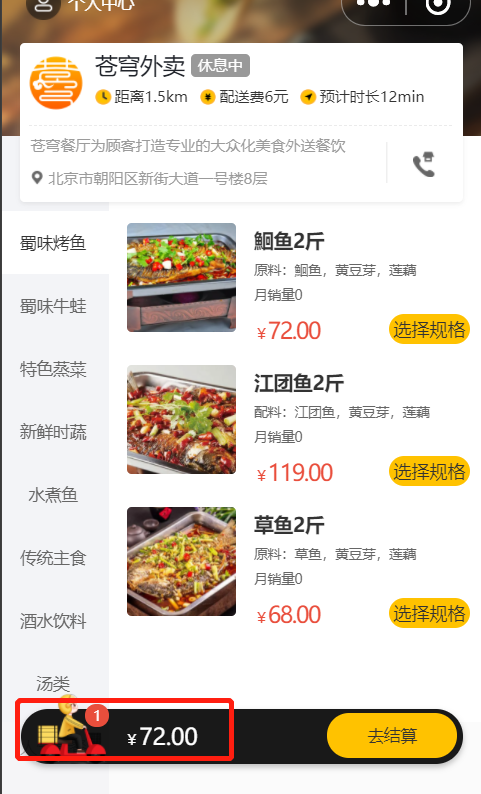 

点击购物车图标

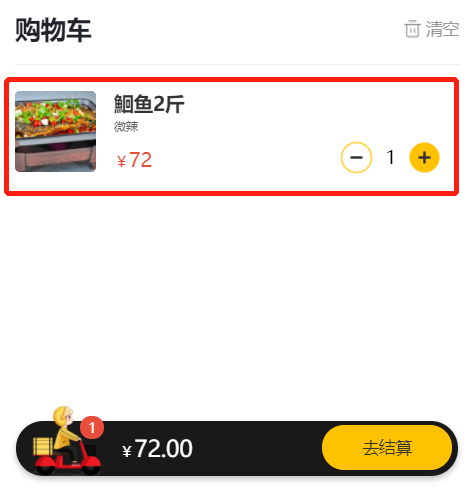 

测试成功。


### 用户隔离与空结果（补充）

准备用户A、B，各有不同购物车数据。分别用自己的token查询，只看到各自条目；在A请求里增加任意userId参数也不能改变查询身份。

验证未登录或过期token返回401；内部缺失上下文时拒绝，不查全部行。空购物车返回[]，多规格条目能分别显示，金额计算使用单价与数量。刷新小程序后应与数据库一致。


### 4.4 代码提交

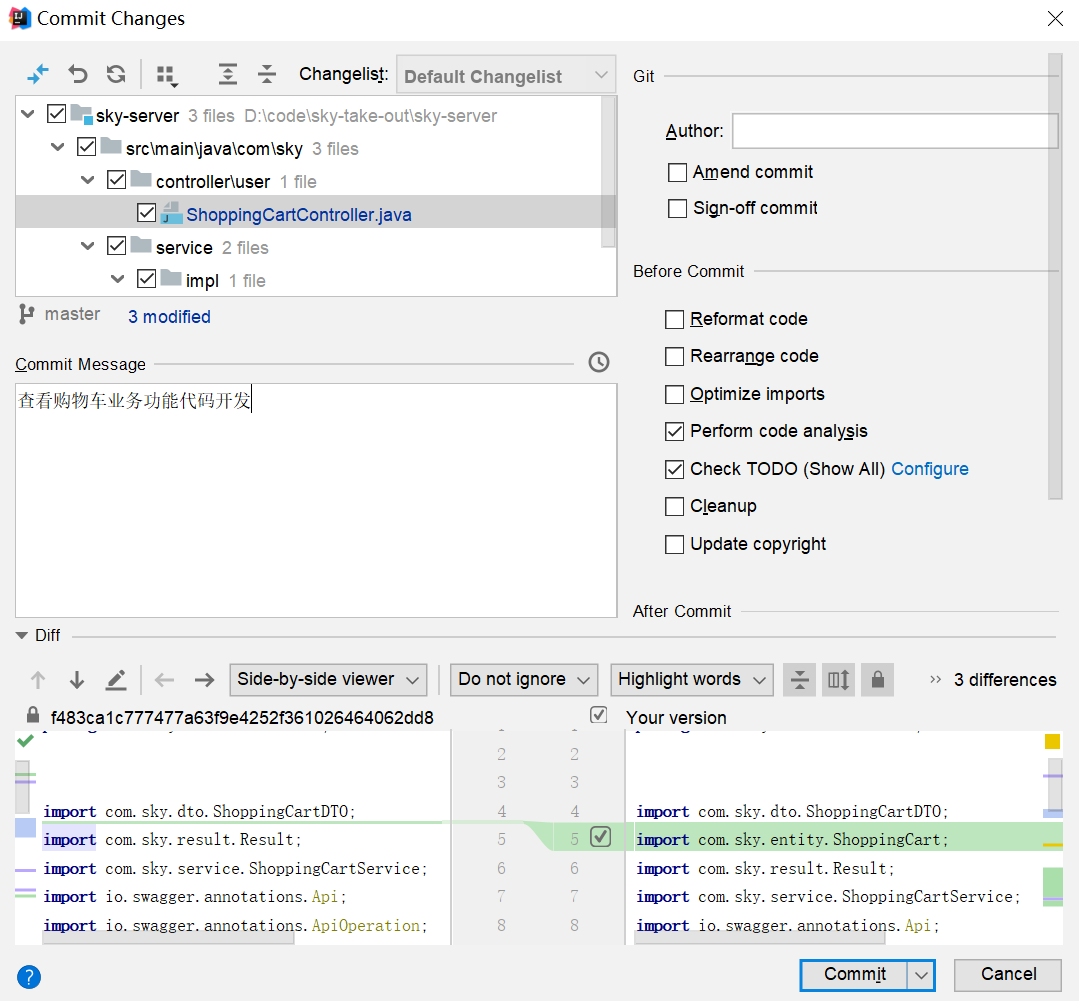 

后续步骤和其它功能代码提交一致，不再赘述。


## 5. 清空购物车

> **PPT对照：** 第60—69页。


### 5.1 需求分析和设计

> **PPT对照：** 第61—62页。

#### 5.1.1 产品原型

当点击清空按钮时，会把购物车中的数据全部清空。

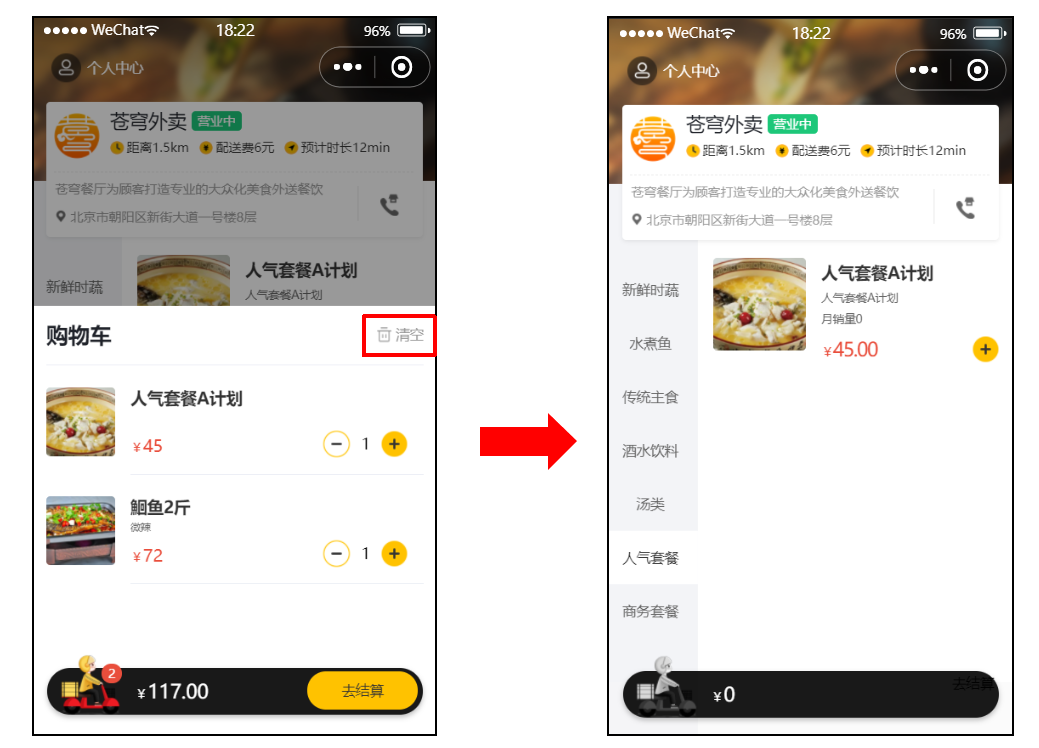 


#### 5.1.2 接口设计

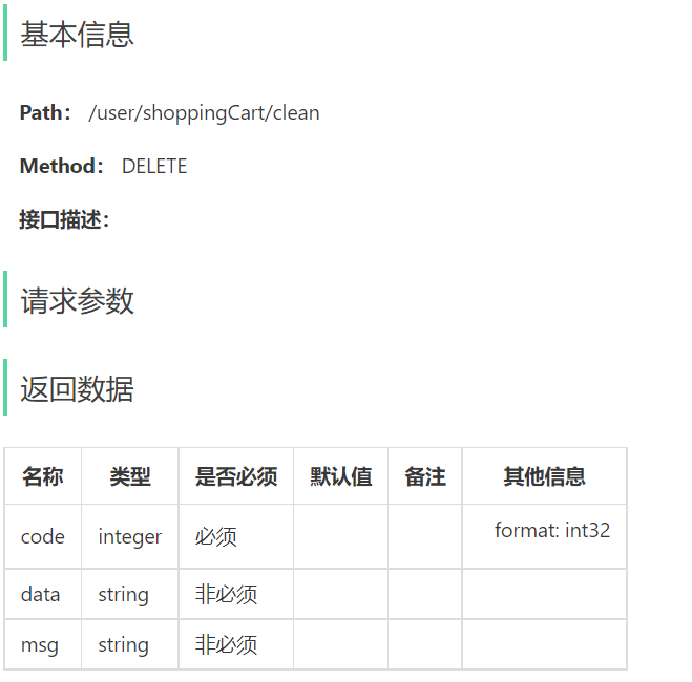


### 清空仅指当前用户购物车（补充）

页面“全部清空”是删除当前登录用户的全部购物车项，不是删除所有用户，也不删除菜品、套餐或商品缓存。

用户再次清空已空购物车，通常可正常返回成功；这是删除当前用户范围内数据的自然行为，不需要为了返回成功再生成空记录。


### 5.2 代码开发

> **PPT对照：** 第64—67页。

#### 5.2.1 Controller层

**在ShoppingCartController中创建清空购物车的方法：**

```java
	/**
     * 清空购物车商品
     * @return
     */
    @DeleteMapping("/clean")
    @ApiOperation("清空购物车商品")
    public Result<String> clean(){
        shoppingCartService.cleanShoppingCart();
        return Result.success();
    }
```


#### 5.2.2 Service层接口

**在ShoppingCartService接口中声明清空购物车的方法：**

```java
	/**
     * 清空购物车商品
     */
    void cleanShoppingCart();
```


#### 5.2.3 Service层实现类

**在ShoppingCartServiceImpl中实现清空购物车的方法：**

```java
	/**
     * 清空购物车商品
     */
    public void cleanShoppingCart() {
        shoppingCartMapper.deleteByUserId(BaseContext.getCurrentId());
    }
```


#### 5.2.4 Mapper层

**在ShoppingCartMapper接口中创建删除购物车数据的方法：**

```java
	/**
     * 根据用户id删除购物车数据
     *
     * @param userId
     */
    @Delete("delete from shopping_cart where user_id = #{userId}")
    void deleteByUserId(Long userId);
```


### 保留用户条件并检查身份（补充）

原Mapper保留 `where user_id = #{userId}`，单条DELETE即可清空本用户所有行，不必先全表查询再循环删。Service同样调用当前用户检查：

```java
@Override
public void cleanShoppingCart() {
    Long userId = requireCurrentUserId();
    shoppingCartMapper.deleteByUserId(userId);
}
```

Mapper参数可显式命名：

```java
@Delete("delete from shopping_cart where user_id = #{userId}")
void deleteByUserId(@org.apache.ibatis.annotations.Param("userId") Long userId);
```

DELETE里的userId必须来自服务端上下文。原SQL对null通常不会删除其他行，但身份缺失也不应悄悄报成功；不要为排查问题去掉where条件。

清空与添加并发时，最终结果由请求及数据库执行顺序影响，清空之后新完成的添加仍可能出现一行。单条删除原子执行不等于锁定这个用户后续所有购物车请求。


### 5.3 功能测试

> **PPT对照：** 第69页。

进入到购物车页面

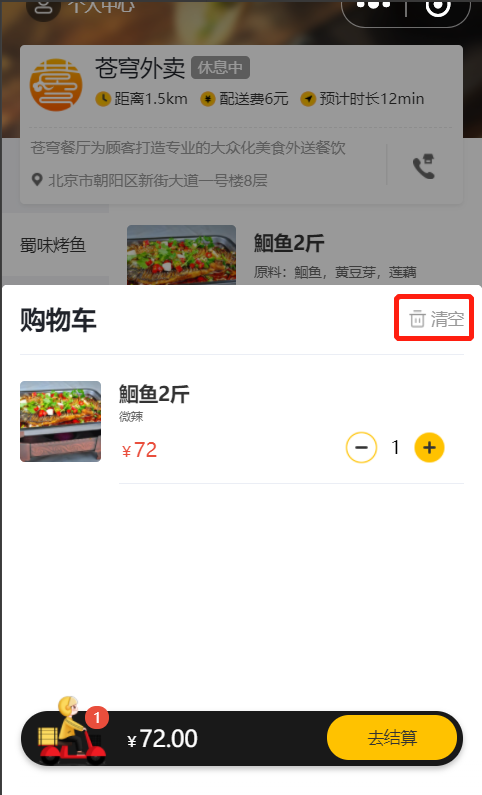 

点击清空

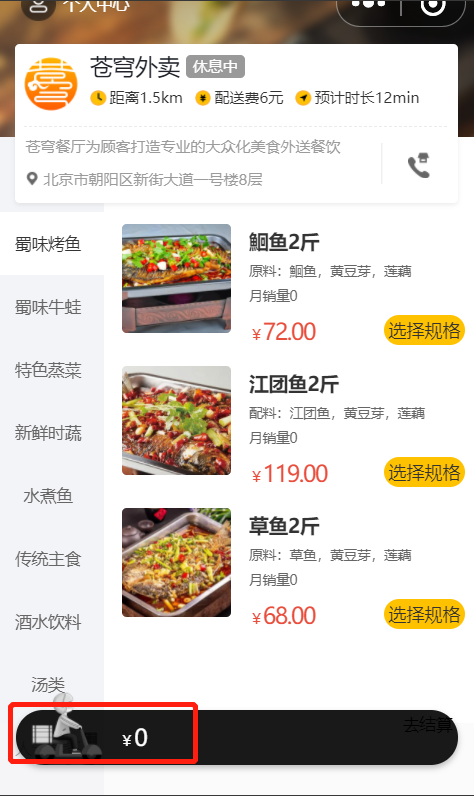 

查看数据库中的数据

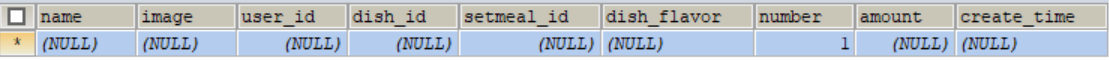 

说明当前用户的购物车数据已全部删除。


### 清空验收（补充）

让A、B都有菜品与套餐，A清空后：A的GET list返回[]，数据库仅A行消失，B数据保持；商品表、dish_*、setmealCache与SHOP_STATUS保持原业务状态。

再次清空A应按接口约定成功；B继续能查询自己的数据。验证未认证请求被拒绝，并在测试环境观察添加与清空并发的结果，不能仅凭页面图标变空认定所有用户隔离都正确。


### 5.4 代码提交

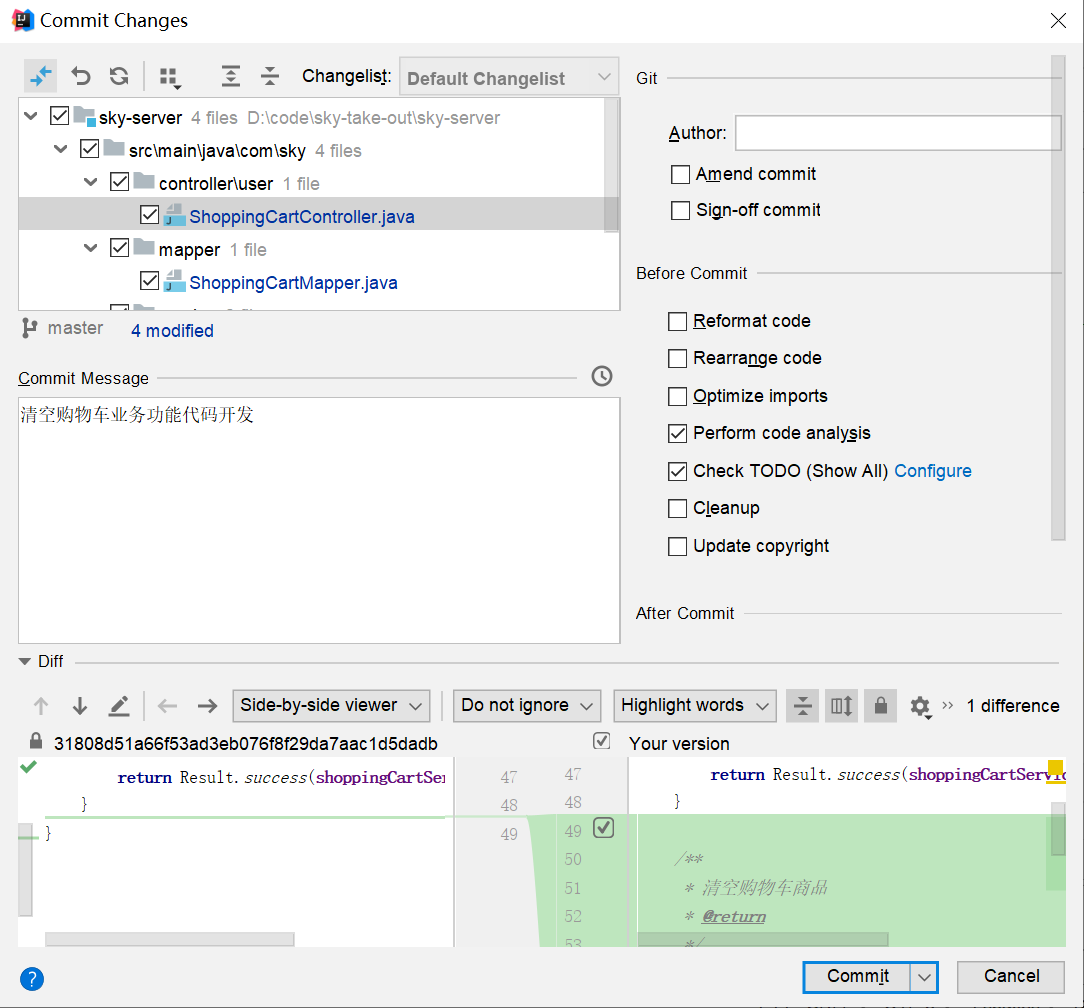 

后续步骤和其它功能代码提交一致，不再赘述。


## 复习速查与本章验收（补充）

| 内容 | 核心记忆 |
| --- | --- |
| 菜品缓存 | dish_分类id，保存List<DishVO>及口味 |
| 空结果 | []也是有效缓存结果，不用size>0判断命中 |
| 失效范围 | 新增一类；跨类修改考虑旧、新类；批量可清整域 |
| 一致性 | 写库后删缓存，仍有并发重填旧值与删除失败问题 |
| Cacheable | 命中跳过目标方法，缓存方法返回值 |
| CachePut | 总执行方法，再以返回值更新缓存 |
| CacheEvict | 默认成功返回后清理，allEntries只清当前缓存名称 |
| CacheManager | 决定底层、序列化和TTL，不等于RedisTemplate配置 |
| 购物车存储 | MySQL shopping_cart，不是本章Redis商品缓存 |
| 购物车唯一项 | 用户、商品类型/id、规范化规格共同决定 |
| number与amount | number数量，amount单价，行合计另算 |
| 用户隔离 | 当前token→userId，查询与删除条件不能省略 |

### 问题排查

| 表现 | 优先检查 |
| --- | --- |
| Redis有空列表却每次查SQL | 缓存命中判断是否要求size>0 |
| 更新后仍显示旧商品 | 失效key、旧新分类、口味变化、并发重填 |
| 商品修改成功却接口报Redis错误 | 数据库提交与缓存删除是两个步骤 |
| 缓存value不能反序列化 | RedisTemplate/CacheManager格式、类是否可序列化 |
| Cacheable未生效 | EnableCaching、实际CacheManager、Spring代理 |
| null key或SpEL错误 | 请求参数、#p0与参数名解析 |
| 清缓存耗时明显 | KEYS、大批量删除与CacheWriter策略 |
| 加购空指针 | 商品不存在、上下文缺失、参数二选一校验 |
| 不同口味被合并 | dishFlavor为null省略条件、规格未规范化 |
| 加购产生重复行 | 多行分支或并发首次插入缺少唯一约束策略 |
| 两次加购只多一份 | Java读后写数量造成并发覆盖 |
| 查看显示其他用户数据 | userId条件被动态省略、身份未清理 |
| 清空后又出现商品 | 并发添加或页面未重新查询，不直接判定删除失败 |

### 跟练验收清单

- [ ] 同分类再次读取不再执行商品与口味SQL，空分类也能短期命中。
- [ ] 缓存TTL、序列化和所在数据库明确，旧缓存格式不混用。
- [ ] 新增、修改、跨分类、删除、启停售后失效范围正确。
- [ ] 说明缓存清理与数据库写入并不构成自动分布式事务。
- [ ] 套餐实际使用预期CacheManager，Cacheable/CacheEvict生效。
- [ ] Spring Cache演示工程与业务用户模块分开，没导入演示deleteAll。
- [ ] 购物车商品id二选一、商品存在可售、规格校验规则明确。
- [ ] 同用户同商品同规格加数量，不同规格与不同用户独立。
- [ ] 无规格与历史NULL匹配正确，多行异常不再插新行。
- [ ] userId缺失时拒绝，不省略用户查询条件。
- [ ] 已有行原子加一，并明确首次并发插入的唯一性处理方案。
- [ ] 查看空列表、金额与排序正确，清空只影响当前用户。

### 自测问题

1. 为什么缓存List<DishVO>还能减少口味查询SQL？
2. 原代码写入[]后，为什么下一次还会查询数据库？
3. 修改菜品所属分类时，只删新分类缓存会遗漏什么？
4. 数据库写完删缓存，为什么仍可能被另一个请求填回旧结果？
5. 为什么RedisTemplate的序列化配置不自动等于RedisCacheManager配置？
6. 套餐Controller返回Result，Cacheable实际保存什么对象？
7. CachePut与Cacheable对目标方法的执行有什么差别？
8. CacheEvict的allEntries会清空MySQL或整个Redis数据库吗？
9. 为什么#result不能随意当作Cacheable的查询key？
10. 购物车amount是单价还是该行合计？
11. dishFlavor为null时省略条件，可能怎样加错数量？
12. 当前用户id为null，原动态列表SQL会有什么后果？
13. 数据库number=number+1与Java读后加一有什么差别？
14. 加@Transactional为何仍可能插入两条相同的购物车项？
15. 两个商品id包含NULL时，简单复合唯一索引为何未必防重复？
16. 清空请求与新增请求并发，为什么最终仍可能出现一条新行？

后续下单要重新验证商品可售与价格，再把购物车数据转换成订单明细；商品缓存和购物车快照不能代替最终业务校验。
